# Tipologi 17 Kapanewon Kabupaten Sleman: Klasterisasi Demografi & Layanan Pendidikan (2021)

**Mata Kuliah:** Analitika Perkotaan  
**Metode:** K-Means Clustering, Hierarchical Clustering (Ward), Principal Component Analysis (PCA)  
**Lingkungan:** Python (`conda activate analitika-perkotaan`)

### Sumber Data Resmi (`data/raw/`)
Seluruh tabel berasal dari **BPS Kabupaten Sleman** (unduhan Query Builder):
1. *Jumlah Penduduk Menurut Kecamatan dan Jenis Kelamin (2020–2027)* — Proyeksi Penduduk BPS 2015–2045
2. *Kepadatan Penduduk & Luas Wilayah Menurut Kecamatan (2020–2022)* — Sensus Penduduk 2020
3. *Banyaknya Sekolah Menurut Tingkat Pendidikan dan Kecamatan (2020–2021)* — Kemendikbud
4. *Jumlah Desa yang Memiliki Fasilitas Sekolah (2020–2021)* — BPS Podes

> **Tahun Analisis Utama: 2021** (satu-satunya tahun yang lengkap dan konsisten pada seluruh tabel). Tahun 2020 digunakan untuk menghitung laju pertumbuhan penduduk 2020→2021.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial import ConvexHull
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

warnings.filterwarnings('ignore')
RANDOM_STATE = 42

# Resolusi path proyek secara otomatis (aman dijalankan dari root maupun dari folder notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW_DIR = ROOT / 'data' / 'raw'
PROC_DIR = ROOT / 'data' / 'processed'
FIG_DIR = ROOT / 'output' / 'figures'
PROC_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Gaya visualisasi editorial (bersih, kontras tinggi, siap laporan & presentasi)
plt.rcParams.update({
    'figure.dpi': 130,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.2,
    'savefig.facecolor': 'white',
    'figure.facecolor': 'white',
    'axes.facecolor': '#FCFDFE',
    'axes.edgecolor': '#CBD5E1',
    'axes.linewidth': 0.9,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.color': '#E2E8F0',
    'grid.linestyle': '--',
    'grid.linewidth': 0.7,
    'grid.alpha': 0.8,
    'font.family': 'DejaVu Sans',
    'text.color': '#0F172A',
    'axes.labelcolor': '#334155',
    'xtick.color': '#475569',
    'ytick.color': '#334155',
    'axes.titleweight': 'bold',
})

SOURCE_NOTE = 'Sumber: Olahan data BPS Kabupaten Sleman (SP2020, Proyeksi Penduduk, Podes) & Kemendikbud, Tahun 2021'
print(f'Project root : {ROOT}')
print(f'Data mentah  : {RAW_DIR}')
print(f'Data olahan  : {PROC_DIR}')
print(f'Output grafik: {FIG_DIR}')

Project root : C:\Users\LENOVO\Documents\tugas-besar-analitika-perkotaan
Data mentah  : C:\Users\LENOVO\Documents\tugas-besar-analitika-perkotaan\data\raw
Data olahan  : C:\Users\LENOVO\Documents\tugas-besar-analitika-perkotaan\data\processed
Output grafik: C:\Users\LENOVO\Documents\tugas-besar-analitika-perkotaan\output\figures


## 1. Memuat & Memvalidasi Data Mentah
Sel ini membaca dua file tabel BPS dari `data/raw/`. Tanda `-` (tidak ada fasilitas pada tabel BPS) dikonversi menjadi `0`.

In [2]:
def find_raw(pattern):
    matches = sorted(RAW_DIR.glob(pattern))
    assert matches, f'File tidak ditemukan di {RAW_DIR}: {pattern}'
    return matches[0]

F_SEKOLAH = find_raw('*20.17.54*.xlsx')
F_PENDUDUK = find_raw('*20.20.19*.xlsx')

KEC = [
    'Moyudan', 'Minggir', 'Seyegan', 'Godean', 'Gamping', 'Mlati', 'Depok', 'Berbah',
    'Prambanan', 'Kalasan', 'Ngemplak', 'Ngaglik', 'Sleman', 'Tempel', 'Turi', 'Pakem', 'Cangkringan'
]

def parse_bps_table(path, sheet, names, years):
    raw = pd.read_excel(path, sheet_name=sheet, header=None)
    raw = raw[raw[0].isin(KEC)].set_index(0)
    raw = raw.iloc[:, :len(names) * len(years)]
    raw = raw.apply(pd.to_numeric, errors='coerce').fillna(0)
    raw.columns = pd.MultiIndex.from_tuples([(n, y) for n in names for y in years])
    return raw.loc[KEC]

sek = parse_bps_table(F_SEKOLAH, 1, ['TK', 'RA', 'SD', 'MI', 'SMP', 'MTs', 'SMA', 'MA', 'SMK'], [2020, 2021])
desa = parse_bps_table(F_SEKOLAH, 0, ['SD', 'SMP', 'SMA', 'SMK', 'PT'], [2020, 2021])
pend = parse_bps_table(F_PENDUDUK, 0, ['L', 'P', 'Total'], list(range(2020, 2028)))
kep = parse_bps_table(F_PENDUDUK, 1, ['Pop', 'Luas', 'Dens'], [2020, 2021, 2022])

# Validasi silang terhadap baris total KABUPATEN SLEMAN di file sumber
cek = pd.DataFrame([
    {'Indikator (2021)': 'Total Penduduk (jiwa)', 'Hasil Olahan': int(pend[('Total', 2021)].sum()), 'Total File BPS': 1136474},
    {'Indikator (2021)': 'Luas Wilayah (km2)',    'Hasil Olahan': round(kep[('Luas', 2021)].sum(), 2), 'Total File BPS': 574.82},
    {'Indikator (2021)': 'Jumlah TK (unit)',      'Hasil Olahan': int(sek[('TK', 2021)].sum()), 'Total File BPS': 511},
    {'Indikator (2021)': 'Jumlah SD (unit)',      'Hasil Olahan': int(sek[('SD', 2021)].sum()), 'Total File BPS': 512},
    {'Indikator (2021)': 'Jumlah SMP (unit)',     'Hasil Olahan': int(sek[('SMP', 2021)].sum()), 'Total File BPS': 120},
])
cek['Status'] = np.where(cek['Hasil Olahan'] == cek['Total File BPS'], 'COCOK', 'PERLU CEK')
display(cek)

,Indikator (2021),Hasil Olahan,Total File BPS,Status
0,Total Penduduk (jiwa),1136474.00,1136474.00,COCOK
1,Luas Wilayah (km2),574.82,574.82,COCOK
2,Jumlah TK (unit),511.00,511.00,COCOK
3,Jumlah SD (unit),512.00,512.00,COCOK
4,Jumlah SMP (unit),120.00,120.00,COCOK


## 2. Feature Engineering (Dataset Analisis 2021)
Agar kapanewon berpenduduk besar (misal Depok) dan kecil (misal Cangkringan) dapat dibandingkan secara adil, jumlah sekolah dinormalisasi menjadi **rasio per 10.000 penduduk** dan **kepadatan sekolah per km²**. Sekolah umum dan madrasah digabung per jenjang (`TK+RA`, `SD+MI`, `SMP+MTs`, `SMA+MA+SMK`).

In [3]:
Y = 2021
pop = pend[('Total', Y)]
s = lambda col: sek[(col, Y)]

tk_ra = s('TK') + s('RA')
sd_mi = s('SD') + s('MI')
smp_mts = s('SMP') + s('MTs')
menengah = s('SMA') + s('MA') + s('SMK')
total_sek = tk_ra + sd_mi + smp_mts + menengah

df = pd.DataFrame(index=KEC)
df.index.name = 'kapanewon'
df['penduduk'] = pop
df['luas_km2'] = kep[('Luas', Y)]
df['kepadatan'] = kep[('Dens', Y)]
df['pertumbuhan_pct'] = (pend[('Total', Y)] / pend[('Total', Y - 1)] - 1) * 100
df['sex_ratio'] = pend[('L', Y)] / pend[('P', Y)] * 100
df['total_sekolah'] = total_sek
df['sekolah_per10k'] = total_sek / pop * 1e4
df['tk_per10k'] = tk_ra / pop * 1e4
df['sd_per10k'] = sd_mi / pop * 1e4
df['smp_per10k'] = smp_mts / pop * 1e4
df['menengah_per10k'] = menengah / pop * 1e4
df['sekolah_per_km2'] = total_sek / df['luas_km2']
df['desa_PT'] = desa[('PT', Y)]
df['porsi_madrasah_pct'] = (s('RA') + s('MI') + s('MTs') + s('MA')) / total_sek * 100

FEATURES = [
    'kepadatan', 'pertumbuhan_pct', 'tk_per10k', 'sd_per10k', 'smp_per10k',
    'menengah_per10k', 'sekolah_per_km2', 'desa_PT', 'porsi_madrasah_pct'
]

# Label bahasa Indonesia yang rapi untuk seluruh visualisasi
FEAT_LABEL = {
    'kepadatan': 'Kepadatan Penduduk\n(jiwa/km²)',
    'pertumbuhan_pct': 'Pertumbuhan Penduduk\n(%/tahun)',
    'tk_per10k': 'TK & RA\n(/10rb jiwa)',
    'sd_per10k': 'SD & MI\n(/10rb jiwa)',
    'smp_per10k': 'SMP & MTs\n(/10rb jiwa)',
    'menengah_per10k': 'SMA/MA/SMK\n(/10rb jiwa)',
    'sekolah_per_km2': 'Kepadatan Sekolah\n(unit/km²)',
    'desa_PT': 'Desa dgn\nPerguruan Tinggi',
    'porsi_madrasah_pct': 'Porsi Madrasah\n(%)',
}
FEAT_SHORT = {k: v.replace('\n', ' ') for k, v in FEAT_LABEL.items()}

df.round(2).to_csv(PROC_DIR / 'dataset_kapanewon_2021.csv')
print(f'Dataset bersih tersimpan di: {PROC_DIR / "dataset_kapanewon_2021.csv"}')
display(df.round(2))

Dataset bersih tersimpan di: C:\Users\LENOVO\Documents\tugas-besar-analitika-perkotaan\data\processed\dataset_kapanewon_2021.csv


,penduduk,luas_km2,kepadatan,pertumbuhan_pct,sex_ratio,total_sekolah,sekolah_per10k,tk_per10k,sd_per10k,smp_per10k,menengah_per10k,sekolah_per_km2,desa_PT,porsi_madrasah_pct
kapanewon,,,,,,,,,,,,,,
Moyudan,33842.0,27.62,1225.27,0.98,99.19,53.0,15.66,5.32,6.80,1.48,2.07,1.92,0.0,11.32
Minggir,32459.0,27.27,1190.28,1.09,95.55,55.0,16.94,6.78,8.01,1.23,0.92,2.02,1.0,12.73
Seyegan,51967.0,26.63,1951.45,1.44,98.51,57.0,10.97,4.23,5.20,0.58,0.96,2.14,0.0,8.77
Godean,73036.0,26.84,2721.16,1.08,99.82,75.0,10.27,4.52,4.24,1.10,0.41,2.79,0.0,4.00
Gamping,104020.0,29.25,3556.24,0.80,98.81,103.0,9.90,4.61,3.85,0.87,0.58,3.52,3.0,6.80
Mlati,100707.0,28.52,3531.10,0.18,99.10,120.0,11.92,5.06,4.27,1.29,1.29,4.21,2.0,8.33
Depok,131242.0,35.55,3691.76,0.18,98.42,160.0,12.19,5.33,4.04,1.14,1.68,4.50,3.0,9.38
Berbah,59976.0,22.99,2608.79,1.65,98.86,60.0,10.00,4.00,3.83,1.00,1.17,2.61,1.0,5.00
Prambanan,53859.0,41.35,1302.52,1.40,97.39,72.0,13.37,4.83,5.38,1.67,1.49,1.74,0.0,2.78


## 3. Eksplorasi Data (EDA): Korelasi Antar Indikator
Matriks korelasi segitiga bawah memperlihatkan hubungan antar indikator perkotaan sebelum klasterisasi.

,mean,std,min,50%,max
Kepadatan Penduduk (jiwa/km²),2074.29,986.50,656.14,1951.45,3691.76
Pertumbuhan Penduduk (%/tahun),1.05,0.44,0.18,1.09,1.65
TK & RA (/10rb jiwa),5.12,0.70,4.00,5.21,6.78
SD & MI (/10rb jiwa),5.30,1.37,3.83,5.20,8.01
SMP & MTs (/10rb jiwa),1.21,0.37,0.58,1.14,2.12
SMA/MA/SMK (/10rb jiwa),1.23,0.51,0.41,1.10,2.39
Kepadatan Sekolah (unit/km²),2.51,0.99,1.00,2.43,4.50
Desa dgn Perguruan Tinggi,0.94,1.14,0.00,1.00,3.00
Porsi Madrasah (%),9.47,4.80,2.78,8.77,17.74


findfont: Failed to find font weight semibold, now using 700.


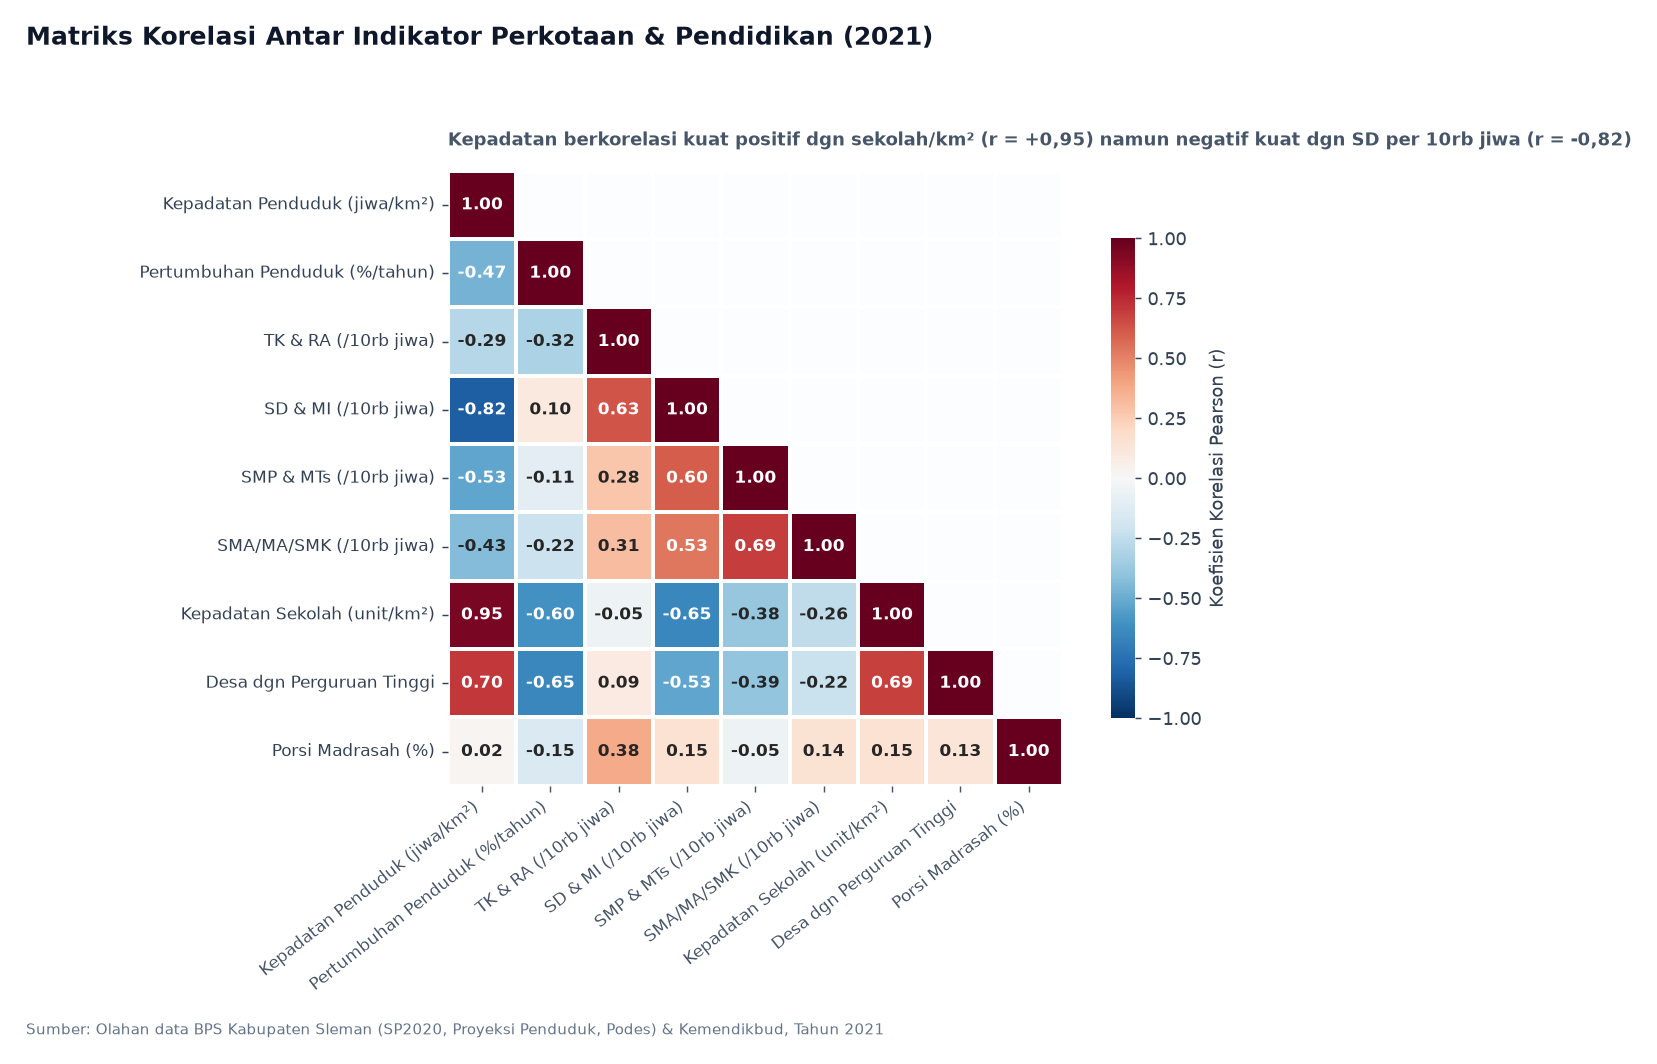

In [4]:
display(df[FEATURES].rename(columns=FEAT_SHORT).describe().round(2).T[['mean', 'std', 'min', '50%', 'max']])

corr = df[FEATURES].corr()
corr.index = [FEAT_SHORT[c] for c in corr.index]
corr.columns = [FEAT_SHORT[c] for c in corr.columns]
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
    vmin=-1, vmax=1, square=True, linewidths=1.2, linecolor='white',
    cbar_kws={'shrink': 0.78, 'label': 'Koefisien Korelasi Pearson (r)'},
    annot_kws={'size': 9.5, 'weight': 'semibold'}, ax=ax
)
ax.grid(False)
ax.set_xticklabels(ax.get_xticklabels(), rotation=38, ha='right', fontsize=9.5)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=9.5)
fig.suptitle('Matriks Korelasi Antar Indikator Perkotaan & Pendidikan (2021)',
             fontsize=14, fontweight='bold', x=0.04, y=0.98, ha='left')
ax.set_title('Kepadatan berkorelasi kuat positif dgn sekolah/km² (r = +0,95) namun negatif kuat dgn SD per 10rb jiwa (r = -0,82)',
             fontsize=10, color='#475569', loc='left', pad=14)
fig.text(0.04, 0.01, SOURCE_NOTE, fontsize=8.5, color='#64748B')
plt.tight_layout(rect=[0, 0.03, 1, 0.94])
plt.savefig(FIG_DIR / '01_korelasi_fitur.png')
plt.show()

## 4. Standarisasi & Penentuan Jumlah Klaster Optimal
Seluruh fitur distandarisasi (*z-score*) karena satuannya berbeda-beda. Jumlah klaster dievaluasi pada rentang $k = 2\dots 6$ menggunakan **Elbow Method (Inertia)**, **Silhouette Score**, dan **Davies-Bouldin Index**.

,k,Inertia,Silhouette,Davies-Bouldin
0,2,97.376,0.274,1.252
1,3,64.541,0.298,1.086
2,4,51.943,0.277,1.050
3,5,41.494,0.296,0.938
4,6,35.271,0.268,0.811


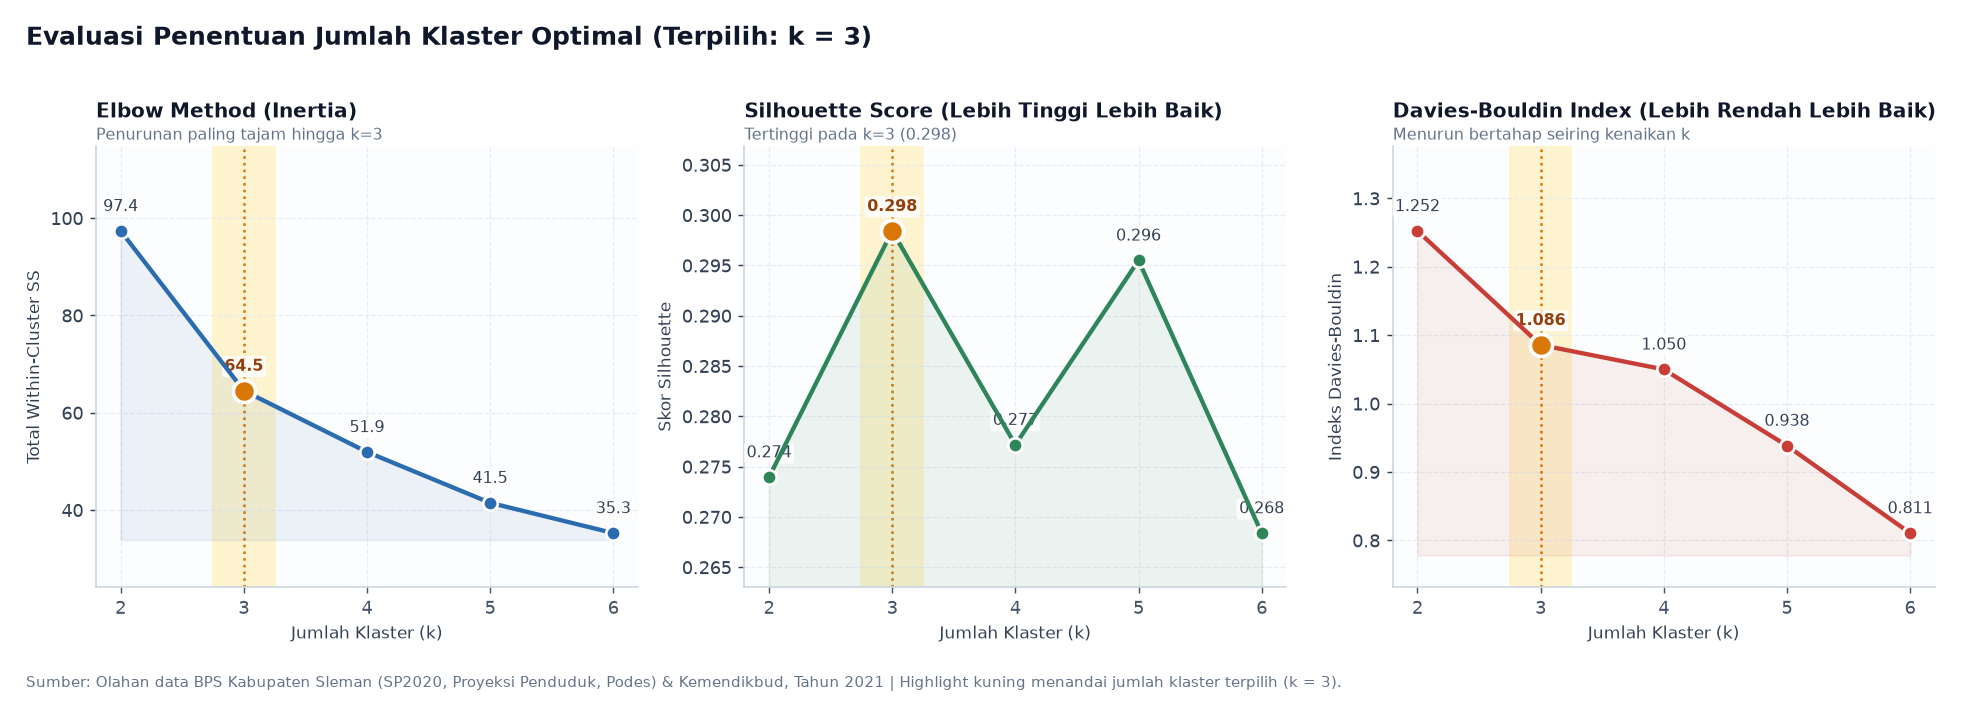

In [5]:
scaler = StandardScaler()
X = scaler.fit_transform(df[FEATURES])

ks = list(range(2, 7))
inertia, sil, dbi = [], [], []
for k in ks:
    m = KMeans(n_clusters=k, n_init=50, random_state=RANDOM_STATE).fit(X)
    inertia.append(m.inertia_)
    sil.append(silhouette_score(X, m.labels_))
    dbi.append(davies_bouldin_score(X, m.labels_))

# Pilih k otomatis dari silhouette tertinggi (isi angka misal 4 untuk override manual)
K_MANUAL = None
K = K_MANUAL or ks[int(np.argmax(sil))]

eval_df = pd.DataFrame({'k': ks, 'Inertia': inertia, 'Silhouette': sil, 'Davies-Bouldin': dbi})
display(eval_df.round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
panels = [
    (axes[0], inertia, 'Elbow Method (Inertia)', 'Total Within-Cluster SS', '#2B6CB0', '{:.1f}', 'Penurunan paling tajam hingga k=3'),
    (axes[1], sil,     'Silhouette Score (Lebih Tinggi Lebih Baik)', 'Skor Silhouette', '#2F855A', '{:.3f}', f'Tertinggi pada k={K} ({max(sil):.3f})'),
    (axes[2], dbi,     'Davies-Bouldin Index (Lebih Rendah Lebih Baik)', 'Indeks Davies-Bouldin', '#C83E37', '{:.3f}', 'Menurun bertahap seiring kenaikan k'),
]

for ax, vals, title, ylabel, color, fmt, sub in panels:
    ax.axvspan(K - 0.25, K + 0.25, color='#FEF3C7', alpha=0.85, zorder=1)
    ax.axvline(K, color='#D97706', linestyle=':', linewidth=1.4, zorder=2)
    ax.plot(ks, vals, '-o', color=color, linewidth=2.4, markersize=8, markeredgecolor='white', markeredgewidth=1.5, zorder=4)
    ax.fill_between(ks, min(vals) * 0.96, vals, color=color, alpha=0.08, zorder=2)
    idx_k = ks.index(K)
    ax.scatter([K], [vals[idx_k]], s=150, color='#D97706', edgecolor='white', linewidth=2, zorder=5)
    span = max(vals) - min(vals)
    ax.set_ylim(min(vals) - span * 0.18, max(vals) + span * 0.28)
    for x_v, y_v in zip(ks, vals):
        weight = 'bold' if x_v == K else 'normal'
        txt_col = '#92400E' if x_v == K else '#334155'
        ax.annotate(fmt.format(y_v), (x_v, y_v), xytext=(0, 11), textcoords='offset points',
                    ha='center', fontsize=9, fontweight=weight, color=txt_col,
                    bbox=dict(boxstyle='round,pad=0.15', facecolor='white', edgecolor='none', alpha=0.82))
    ax.set_title(title, fontsize=11, pad=16, loc='left')
    ax.text(0.0, 1.015, sub, transform=ax.transAxes, fontsize=8.8, color='#64748B')
    ax.set_xlabel('Jumlah Klaster (k)', fontsize=9.5)
    ax.set_ylabel(ylabel, fontsize=9.5)
    ax.set_xticks(ks)

fig.suptitle(f'Evaluasi Penentuan Jumlah Klaster Optimal (Terpilih: k = {K})',
             fontsize=14, fontweight='bold', x=0.01, y=1.02, ha='left')
fig.text(0.01, -0.04, SOURCE_NOTE + ' | Highlight kuning menandai jumlah klaster terpilih (k = 3).', fontsize=8.5, color='#64748B')
plt.tight_layout()
plt.savefig(FIG_DIR / '02_evaluasi_jumlah_klaster.png')
plt.show()

## 5. Pemodelan K-Means vs Hierarchical Clustering (Ward)
Kedua metode dibandingkan dengan *Adjusted Rand Index* (ARI) untuk menguji kestabilan pengelompokan. Dendrogram disajikan secara **horizontal** agar seluruh nama kapanewon mudah dibaca tanpa miring.

Silhouette K-Means         : 0.298
Silhouette Hierarki (Ward) : 0.289
Adjusted Rand Index (ARI)  : 0.796
Kapanewon berbeda klaster  : ['Sleman']


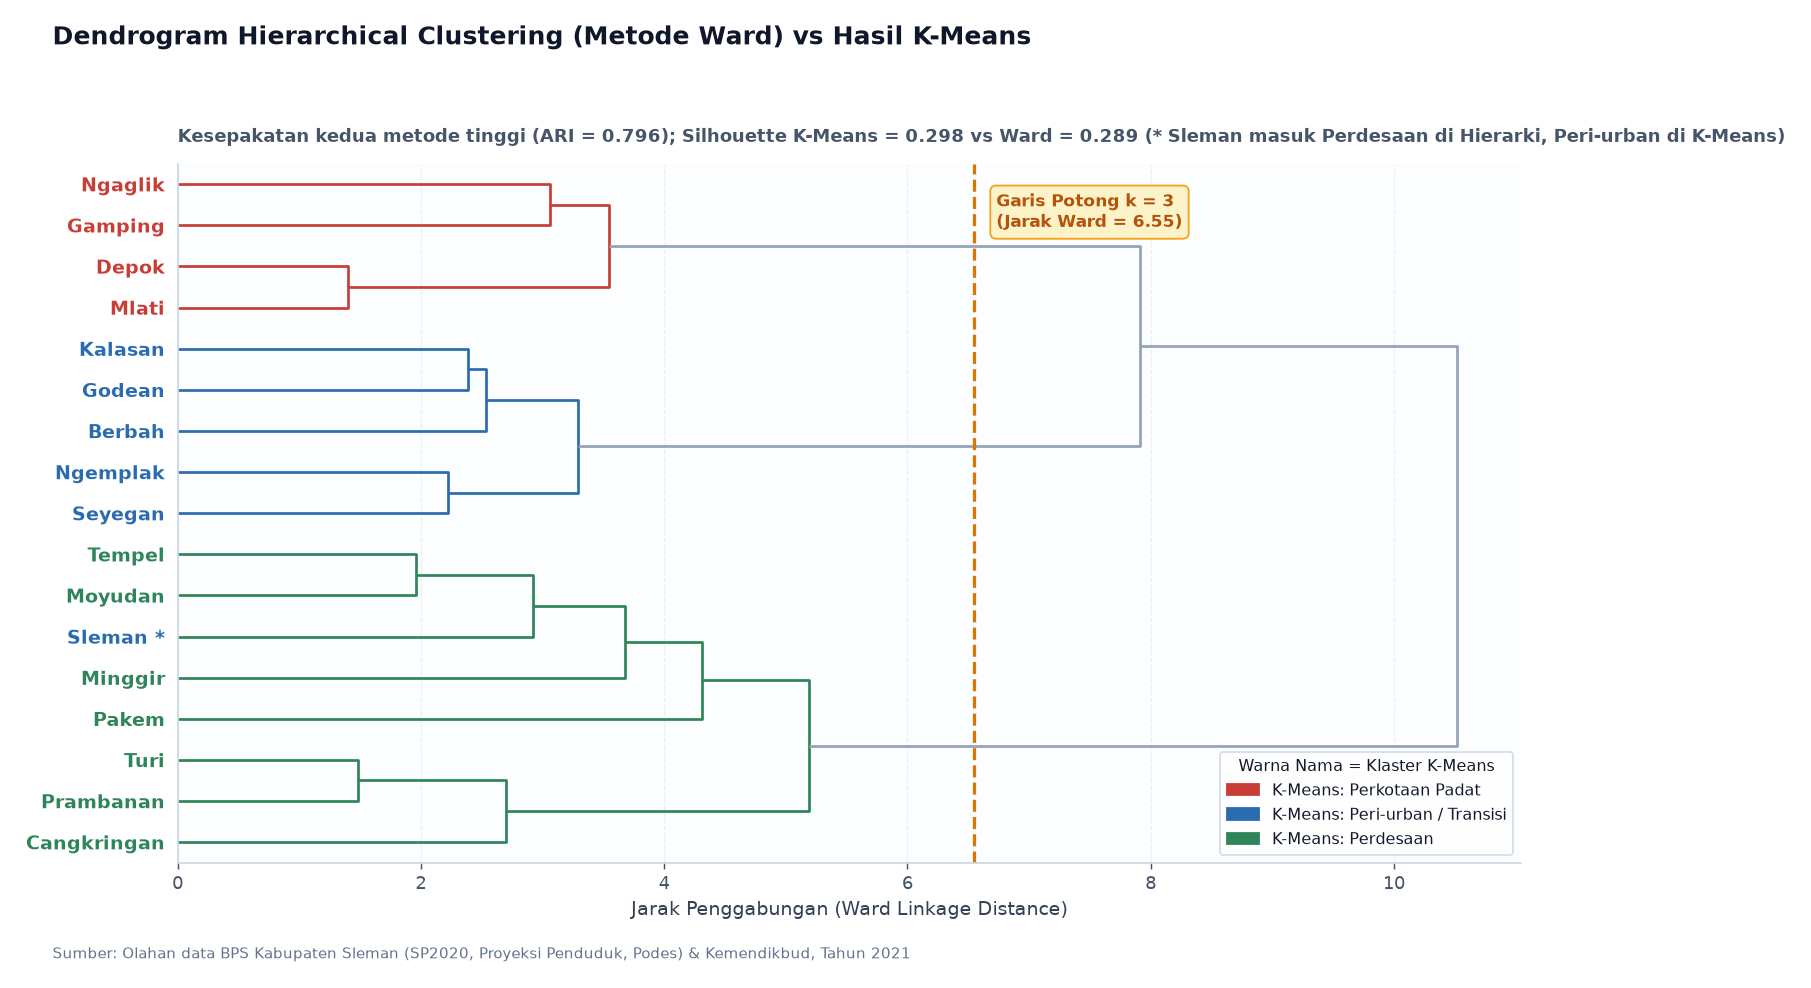

In [6]:
km = KMeans(n_clusters=K, n_init=50, random_state=RANDOM_STATE).fit(X)
hc = AgglomerativeClustering(n_clusters=K, linkage='ward').fit(X)
df['klaster_kmeans'] = km.labels_
df['klaster_hierarki'] = hc.labels_

# Urutkan & beri nama tipologi berdasarkan rata-rata kepadatan penduduk
order = df.groupby('klaster_kmeans')['kepadatan'].mean().sort_values(ascending=False).index.tolist()
if K == 3:
    CLUSTER_NAMES = ['Perkotaan Padat', 'Peri-urban / Transisi', 'Perdesaan']
    PALETTE = {
        'Perkotaan Padat': '#C83E37',
        'Peri-urban / Transisi': '#2B6CB0',
        'Perdesaan': '#2F855A',
    }
else:
    CLUSTER_NAMES = [f'Klaster {i+1}' for i in range(K)]
    PALETTE = dict(zip(CLUSTER_NAMES, sns.color_palette('Set2', K).as_hex()))

label_map = {c: CLUSTER_NAMES[i] for i, c in enumerate(order)}
df['tipologi'] = df['klaster_kmeans'].map(label_map)

# Pemetaan label hierarki ke nama tipologi yang paling sesuai agar mudah dibandingkan
hc_order = df.groupby('klaster_hierarki')['kepadatan'].mean().sort_values(ascending=False).index.tolist()
hc_map = {c: CLUSTER_NAMES[i] for i, c in enumerate(hc_order)}
df['tipologi_hierarki'] = df['klaster_hierarki'].map(hc_map)

sil_km = silhouette_score(X, km.labels_)
sil_hc = silhouette_score(X, hc.labels_)
ari = adjusted_rand_score(km.labels_, hc.labels_)
beda = df.index[df['tipologi'] != df['tipologi_hierarki']].tolist()

print(f'Silhouette K-Means         : {sil_km:.3f}')
print(f'Silhouette Hierarki (Ward) : {sil_hc:.3f}')
print(f'Adjusted Rand Index (ARI)  : {ari:.3f}')
print(f'Kapanewon berbeda klaster  : {beda if beda else "Tidak ada"}')

# Dendrogram Horizontal (lebih rapi dan mudah dibaca, warna cabang selaras palet)
from scipy.cluster.hierarchy import set_link_color_palette
Z_link = linkage(X, method='ward')
cut_dist = (Z_link[-(K - 1), 2] + Z_link[-K, 2]) / 2
set_link_color_palette(['#2F855A', '#2B6CB0', '#C83E37'])

fig, ax = plt.subplots(figsize=(11.8, 7.4))
ddata = dendrogram(
    Z_link, labels=df.index.tolist(), orientation='right',
    color_threshold=cut_dist, above_threshold_color='#94A3B8',
    leaf_font_size=10.5, ax=ax
)
set_link_color_palette(None)

# Perbarui label nama (tambahkan * untuk yang berbeda) & warnai sesuai klaster K-Means
new_labels = [f'{lbl} *' if lbl in beda else lbl for lbl in ddata['ivl']]
ax.set_yticklabels(new_labels)
for tick, raw_name in zip(ax.get_yticklabels(), ddata['ivl']):
    tip = df.loc[raw_name, 'tipologi']
    tick.set_color(PALETTE[tip])
    tick.set_fontweight('bold')

ax.axvline(cut_dist, color='#D97706', linestyle='--', linewidth=1.8)
ax.text(cut_dist + 0.18, ax.get_ylim()[1] * 0.96, f'Garis Potong k = {K}\n(Jarak Ward = {cut_dist:.2f})',
        fontsize=9.5, fontweight='bold', color='#B45309', va='top',
        bbox=dict(boxstyle='round,pad=0.35', facecolor='#FEF3C7', edgecolor='#F59E0B', alpha=0.95))

legend_handles = [mpatches.Patch(color=PALETTE[n], label=f'K-Means: {n}') for n in CLUSTER_NAMES]
ax.legend(handles=legend_handles, title='Warna Nama = Klaster K-Means', loc='lower right',
          frameon=True, facecolor='white', edgecolor='#CBD5E1', fontsize=9, title_fontsize=9)

ax.set_xlabel('Jarak Penggabungan (Ward Linkage Distance)', fontsize=10.5)
ax.set_ylabel('')
ax.grid(axis='x', linestyle='--', alpha=0.7)
ax.grid(axis='y', visible=False)
fig.suptitle('Dendrogram Hierarchical Clustering (Metode Ward) vs Hasil K-Means',
             fontsize=14, fontweight='bold', x=0.03, y=0.98, ha='left')
cat_beda = f' (* {", ".join(beda)} masuk Perdesaan di Hierarki, Peri-urban di K-Means)' if beda else ''
ax.set_title(f'Kesepakatan kedua metode tinggi (ARI = {ari:.3f}); Silhouette K-Means = {sil_km:.3f} vs Ward = {sil_hc:.3f}{cat_beda}',
             fontsize=9.8, color='#475569', loc='left', pad=12)
fig.text(0.03, 0.01, SOURCE_NOTE, fontsize=8.5, color='#64748B')
plt.tight_layout(rect=[0, 0.03, 1, 0.94])
plt.savefig(FIG_DIR / '03_dendrogram_hierarki.png')
plt.show()

## 6. Visualisasi Hasil & Tipologi Wilayah

### 6.1 Peringkat Kepadatan Penduduk vs Ketersediaan Sekolah (Diwarnai Tipologi Klaster)
Dengan pewarnaan langsung menurut tipologi klaster dan garis rata-rata Kabupaten Sleman, tampak jelas kontras antara kepadatan fisik penduduk dan rasio ketersediaan sekolah per 10.000 jiwa.

findfont: Failed to find font weight semibold, now using 700.


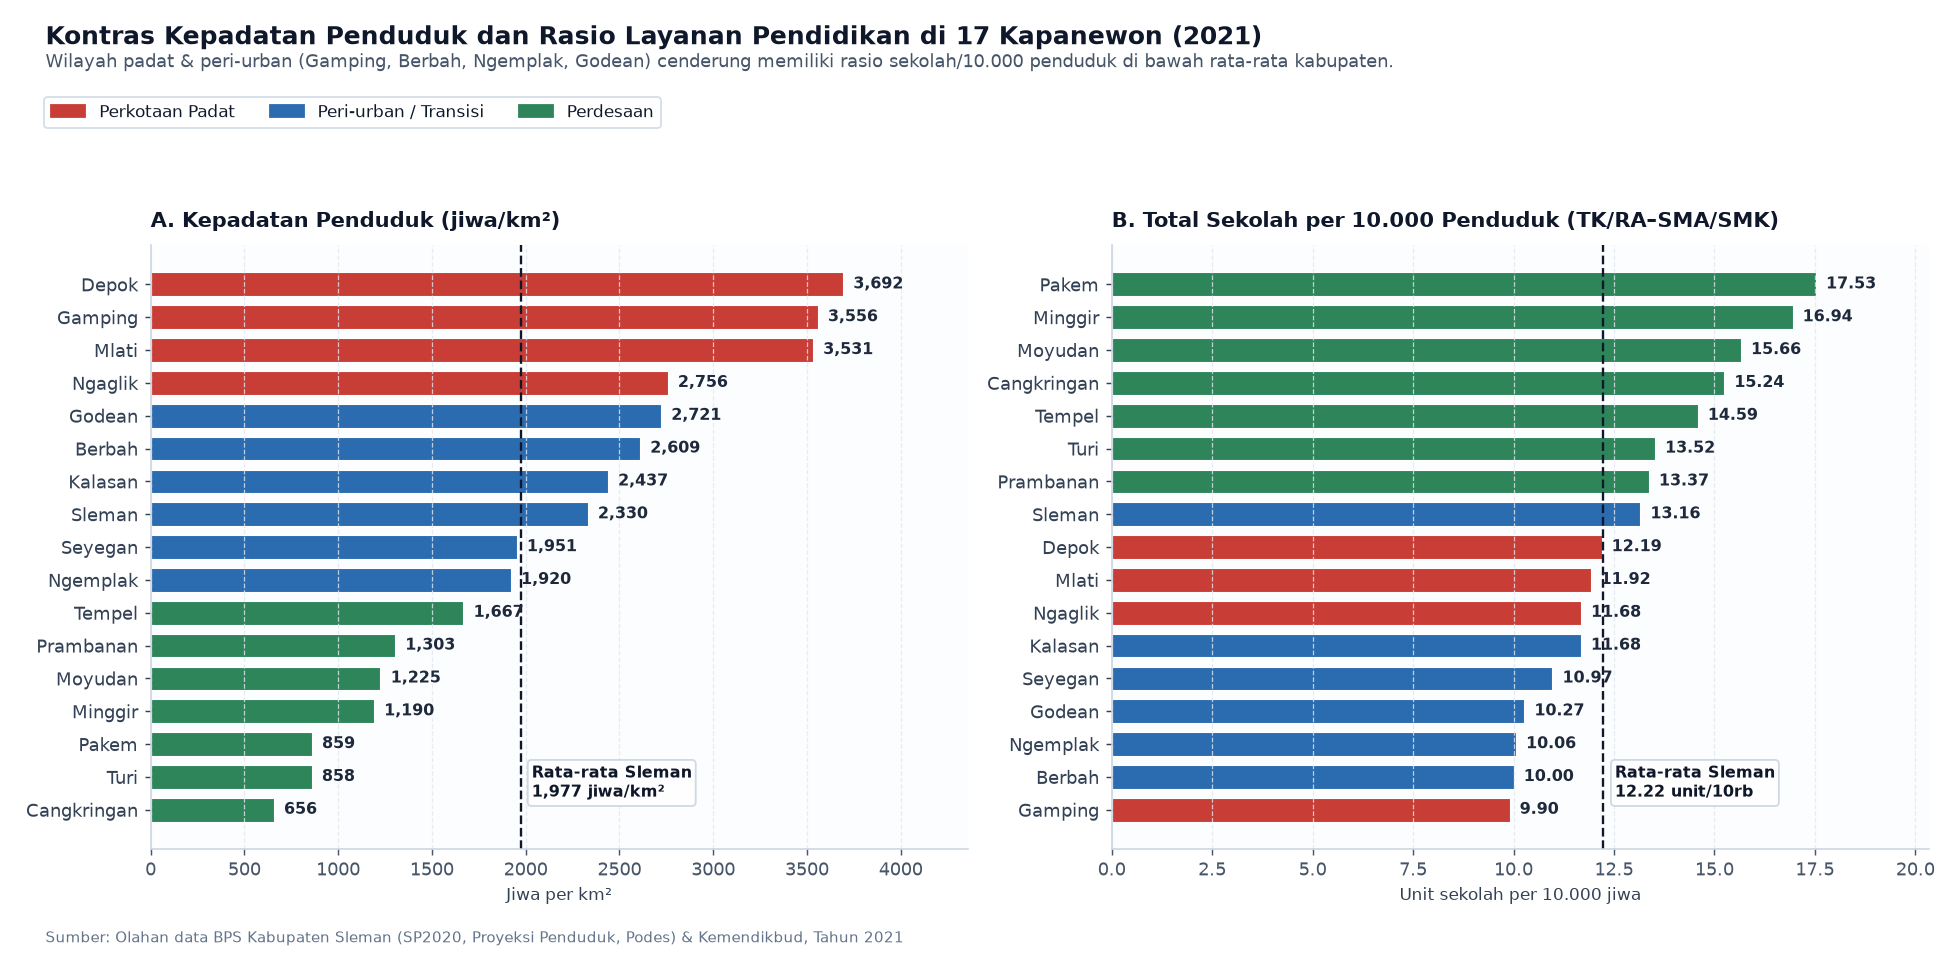

In [7]:
avg_dens = df['penduduk'].sum() / df['luas_km2'].sum()
avg_sek10k = df['total_sekolah'].sum() / df['penduduk'].sum() * 1e4

fig, axes = plt.subplots(1, 2, figsize=(15, 7.2))

# Panel kiri: Kepadatan penduduk
d1 = df.sort_values('kepadatan', ascending=True)
c1 = [PALETTE[t] for t in d1['tipologi']]
axes[0].barh(d1.index, d1['kepadatan'], color=c1, height=0.72, edgecolor='white', linewidth=0.6)
axes[0].axvline(avg_dens, color='#0F172A', linestyle='--', linewidth=1.3)
axes[0].text(avg_dens + 55, 0.4, f'Rata-rata Sleman\n{avg_dens:,.0f} jiwa/km²', fontsize=8.8, fontweight='bold', color='#0F172A',
             bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='#CBD5E1', alpha=0.92))
for y_i, val in enumerate(d1['kepadatan']):
    axes[0].text(val + 55, y_i, f'{val:,.0f}', va='center', fontsize=8.8, color='#1E293B', fontweight='semibold')
axes[0].set_xlim(0, d1['kepadatan'].max() * 1.18)
axes[0].set_title('A. Kepadatan Penduduk (jiwa/km²)', fontsize=11.5, loc='left', pad=10)
axes[0].set_xlabel('Jiwa per km²', fontsize=9.5)
axes[0].grid(axis='y', visible=False)

# Panel kanan: Total sekolah per 10.000 penduduk
d2 = df.sort_values('sekolah_per10k', ascending=True)
c2 = [PALETTE[t] for t in d2['tipologi']]
axes[1].barh(d2.index, d2['sekolah_per10k'], color=c2, height=0.72, edgecolor='white', linewidth=0.6)
axes[1].axvline(avg_sek10k, color='#0F172A', linestyle='--', linewidth=1.3)
axes[1].text(avg_sek10k + 0.3, 0.4, f'Rata-rata Sleman\n{avg_sek10k:.2f} unit/10rb', fontsize=8.8, fontweight='bold', color='#0F172A',
             bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='#CBD5E1', alpha=0.92))
for y_i, val in enumerate(d2['sekolah_per10k']):
    axes[1].text(val + 0.25, y_i, f'{val:.2f}', va='center', fontsize=8.8, color='#1E293B', fontweight='semibold')
axes[1].set_xlim(0, d2['sekolah_per10k'].max() * 1.16)
axes[1].set_title('B. Total Sekolah per 10.000 Penduduk (TK/RA–SMA/SMK)', fontsize=11.5, loc='left', pad=10)
axes[1].set_xlabel('Unit sekolah per 10.000 jiwa', fontsize=9.5)
axes[1].grid(axis='y', visible=False)

handles = [mpatches.Patch(color=PALETTE[n], label=n) for n in CLUSTER_NAMES]
fig.suptitle('Kontras Kepadatan Penduduk dan Rasio Layanan Pendidikan di 17 Kapanewon (2021)',
             fontsize=14, fontweight='bold', x=0.02, y=0.99, ha='left')
fig.text(0.02, 0.945, 'Wilayah padat & peri-urban (Gamping, Berbah, Ngemplak, Godean) cenderung memiliki rasio sekolah/10.000 penduduk di bawah rata-rata kabupaten.',
         fontsize=9.8, color='#475569')
fig.legend(handles=handles, loc='upper left', bbox_to_anchor=(0.015, 0.922), ncol=len(CLUSTER_NAMES),
           frameon=True, facecolor='white', edgecolor='#CBD5E1', fontsize=9.5)
fig.text(0.02, 0.01, SOURCE_NOTE, fontsize=8.5, color='#64748B')
plt.tight_layout(rect=[0, 0.03, 1, 0.86])
plt.savefig(FIG_DIR / '04_peringkat_kepadatan_dan_sekolah.png')
plt.show()

### 6.2 Proyeksi PCA Biplot 2D (Peta Posisi Klaster & Arah Faktor Pendorong)
Dua komponen utama menjelaskan **70,4%** total variansi data (PC1: 45,5% merepresentasikan gradien **Perdesaan → Perkotaan Padat**; PC2: 24,9% merepresentasikan **Laju Pertumbuhan Cepat vs Rasio Layanan Pendidikan**). Ukuran lingkaran proporsional terhadap jumlah penduduk.

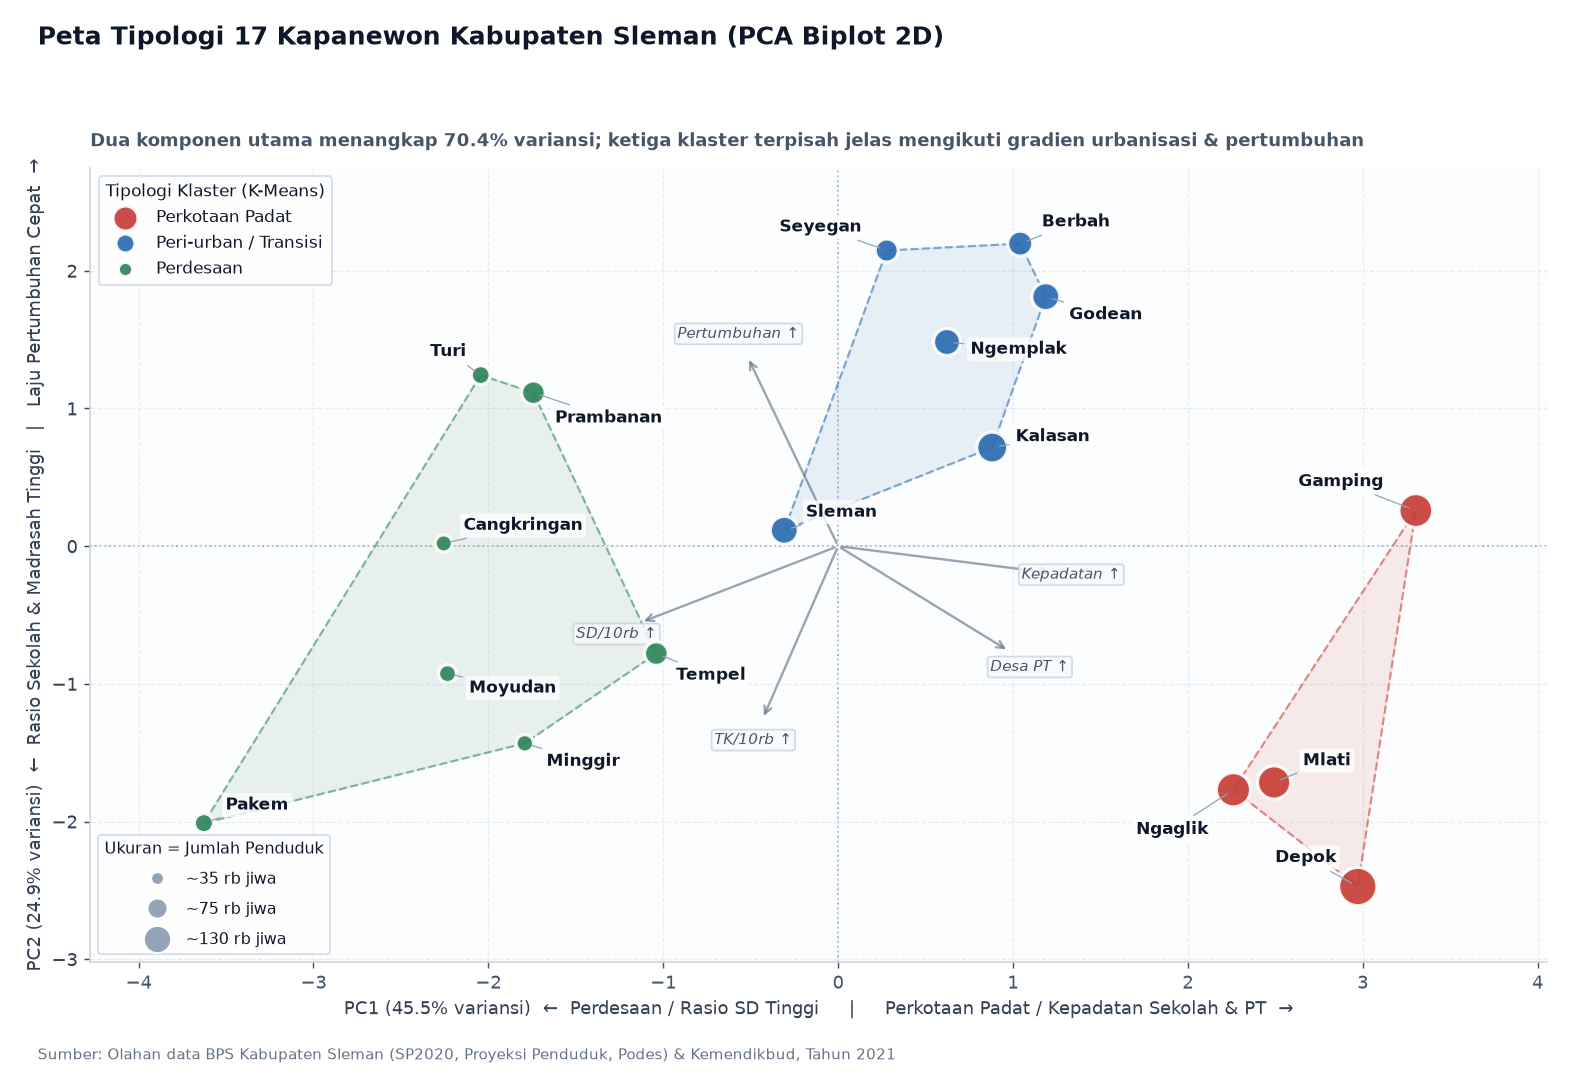

,PC1 (45.5%),PC2 (24.9%)
Kepadatan Penduduk (jiwa/km²),0.47,-0.08
Pertumbuhan Penduduk (%/tahun),-0.20,0.53
TK & RA (/10rb jiwa),-0.17,-0.48
SD & MI (/10rb jiwa),-0.43,-0.21
SMP & MTs (/10rb jiwa),-0.34,-0.24
SMA/MA/SMK (/10rb jiwa),-0.28,-0.35
Kepadatan Sekolah (unit/km²),0.43,-0.24
Desa dgn Perguruan Tinggi,0.38,-0.29
Porsi Madrasah (%),0.00,-0.33


In [8]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
Z = pca.fit_transform(X)
var1, var2 = pca.explained_variance_ratio_ * 100

fig, ax = plt.subplots(figsize=(12, 8.2))
ax.axhline(0, color='#94A3B8', linestyle=':', linewidth=1.0, zorder=1)
ax.axvline(0, color='#94A3B8', linestyle=':', linewidth=1.0, zorder=1)

# Area poligon (convex hull) lembut untuk batas visual setiap klaster
for n in CLUSTER_NAMES:
    pts = Z[(df['tipologi'] == n).values]
    if len(pts) >= 3:
        hull = ConvexHull(pts)
        poly = pts[hull.vertices]
        ax.fill(poly[:, 0], poly[:, 1], color=PALETTE[n], alpha=0.10, zorder=2)
        poly_closed = np.vstack([poly, poly[0]])
        ax.plot(poly_closed[:, 0], poly_closed[:, 1], color=PALETTE[n], linestyle='--', linewidth=1.2, alpha=0.55, zorder=2)

# Panah loading fitur utama (biplot vectors)
key_vectors = {
    'kepadatan': ('Kepadatan ↑', (1.08, 1.05)),
    'desa_PT': ('Desa PT ↑', (1.12, 1.15)),
    'pertumbuhan_pct': ('Pertumbuhan ↑', (1.10, 1.12)),
    'sd_per10k': ('SD/10rb ↑', (1.12, 1.15)),
    'tk_per10k': ('TK/10rb ↑', (1.12, 1.12)),
}
scale_vec = 2.6
for feat, (vlabel, mult) in key_vectors.items():
    idx = FEATURES.index(feat)
    vx, vy = pca.components_[0, idx] * scale_vec, pca.components_[1, idx] * scale_vec
    ax.annotate('', xy=(vx, vy), xytext=(0, 0),
                arrowprops=dict(arrowstyle='->', color='#64748B', lw=1.3, alpha=0.65), zorder=3)
    ax.text(vx * mult[0], vy * mult[1], vlabel, fontsize=8.5, color='#475569', style='italic',
            ha='center', va='center', zorder=3,
            bbox=dict(boxstyle='round,pad=0.18', facecolor='#F8FAFC', edgecolor='#CBD5E1', alpha=0.82))

# Titik kapanewon (ukuran proporsional terhadap jumlah penduduk)
sizes = 90 + (df['penduduk'] - df['penduduk'].min()) / (df['penduduk'].max() - df['penduduk'].min()) * 360
for n in CLUSTER_NAMES:
    m = (df['tipologi'] == n).values
    ax.scatter(Z[m, 0], Z[m, 1], s=sizes[m], color=PALETTE[n], edgecolor='white',
               linewidth=1.8, alpha=0.92, label=n, zorder=5)

# Penempatan label khusus agar 100% bebas tumpang tindih (terutama Ngaglik & Mlati)
custom_offsets = {
    'Ngaglik': (-14, -22),
    'Mlati': (16, 12),
    'Depok': (-12, 16),
    'Gamping': (-18, 16),
    'Turi': (-8, 13),
    'Prambanan': (12, -14),
    'Seyegan': (-14, 13),
    'Berbah': (12, 12),
    'Godean': (13, -10),
    'Ngemplak': (13, -4),
    'Kalasan': (13, 6),
    'Sleman': (12, 10),
    'Cangkringan': (11, 10),
    'Moyudan': (12, -8),
    'Minggir': (12, -10),
    'Tempel': (11, -12),
    'Pakem': (12, 10),
}
for i, kec in enumerate(df.index):
    dx, dy = custom_offsets.get(kec, (10, 8))
    ha = 'right' if dx < 0 else 'left'
    ax.annotate(
        kec, (Z[i, 0], Z[i, 1]), xytext=(dx, dy), textcoords='offset points',
        fontsize=9.5, fontweight='semibold', color='#0F172A', ha=ha, va='center', zorder=6,
        bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='none', alpha=0.78),
        arrowprops=dict(arrowstyle='-', color='#94A3B8', lw=0.7, shrinkA=2, shrinkB=4)
    )

ax.set_xlim(Z[:, 0].min() - 0.65, Z[:, 0].max() + 0.75)
ax.set_ylim(Z[:, 1].min() - 0.55, Z[:, 1].max() + 0.55)
ax.set_xlabel(f'PC1 ({var1:.1f}% variansi)  ←  Perdesaan / Rasio SD Tinggi     |     Perkotaan Padat / Kepadatan Sekolah & PT  →', fontsize=10)
ax.set_ylabel(f'PC2 ({var2:.1f}% variansi)  ←  Rasio Sekolah & Madrasah Tinggi   |   Laju Pertumbuhan Cepat  →', fontsize=10)

# Legend klaster + ukuran penduduk
leg1 = ax.legend(title='Tipologi Klaster (K-Means)', loc='upper left', frameon=True,
                 facecolor='white', edgecolor='#CBD5E1', fontsize=9.5, title_fontsize=9.5, markerscale=0.7)
ax.add_artist(leg1)
size_handles = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#94A3B8', markersize=7,  label='~35 rb jiwa'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#94A3B8', markersize=11, label='~75 rb jiwa'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#94A3B8', markersize=15, label='~130 rb jiwa'),
]
ax.legend(handles=size_handles, title='Ukuran = Jumlah Penduduk', loc='lower left',
          frameon=True, facecolor='white', edgecolor='#CBD5E1', fontsize=8.8, title_fontsize=8.8, labelspacing=0.9)

fig.suptitle('Peta Tipologi 17 Kapanewon Kabupaten Sleman (PCA Biplot 2D)',
             fontsize=14, fontweight='bold', x=0.02, y=0.98, ha='left')
ax.set_title(f'Dua komponen utama menangkap {var1+var2:.1f}% variansi; ketiga klaster terpisah jelas mengikuti gradien urbanisasi & pertumbuhan',
             fontsize=9.8, color='#475569', loc='left', pad=12)
fig.text(0.02, 0.01, SOURCE_NOTE, fontsize=8.5, color='#64748B')
plt.tight_layout(rect=[0, 0.03, 1, 0.94])
plt.savefig(FIG_DIR / '05_pca_biplot_klaster.png')
plt.show()

load_df = pd.DataFrame(pca.components_.T, index=[FEAT_SHORT[f] for f in FEATURES], columns=[f'PC1 ({var1:.1f}%)', f'PC2 ({var2:.1f}%)'])
display(load_df.round(2))

### 6.3 Profil Karakteristik Tiap Klaster (Radar Chart + Perbandingan Z-Score)
Panel kiri (Radar Chart) menampilkan bentuk profil keseluruhan secara intuitif, sedangkan panel kanan (Heatmap Z-Score dengan **angka aktual**) memudahkan pembacaan nilai eksak tiap indikator untuk laporan.

findfont: Failed to find font weight semibold, now using 700.


findfont: Failed to find font weight semibold, now using 700.


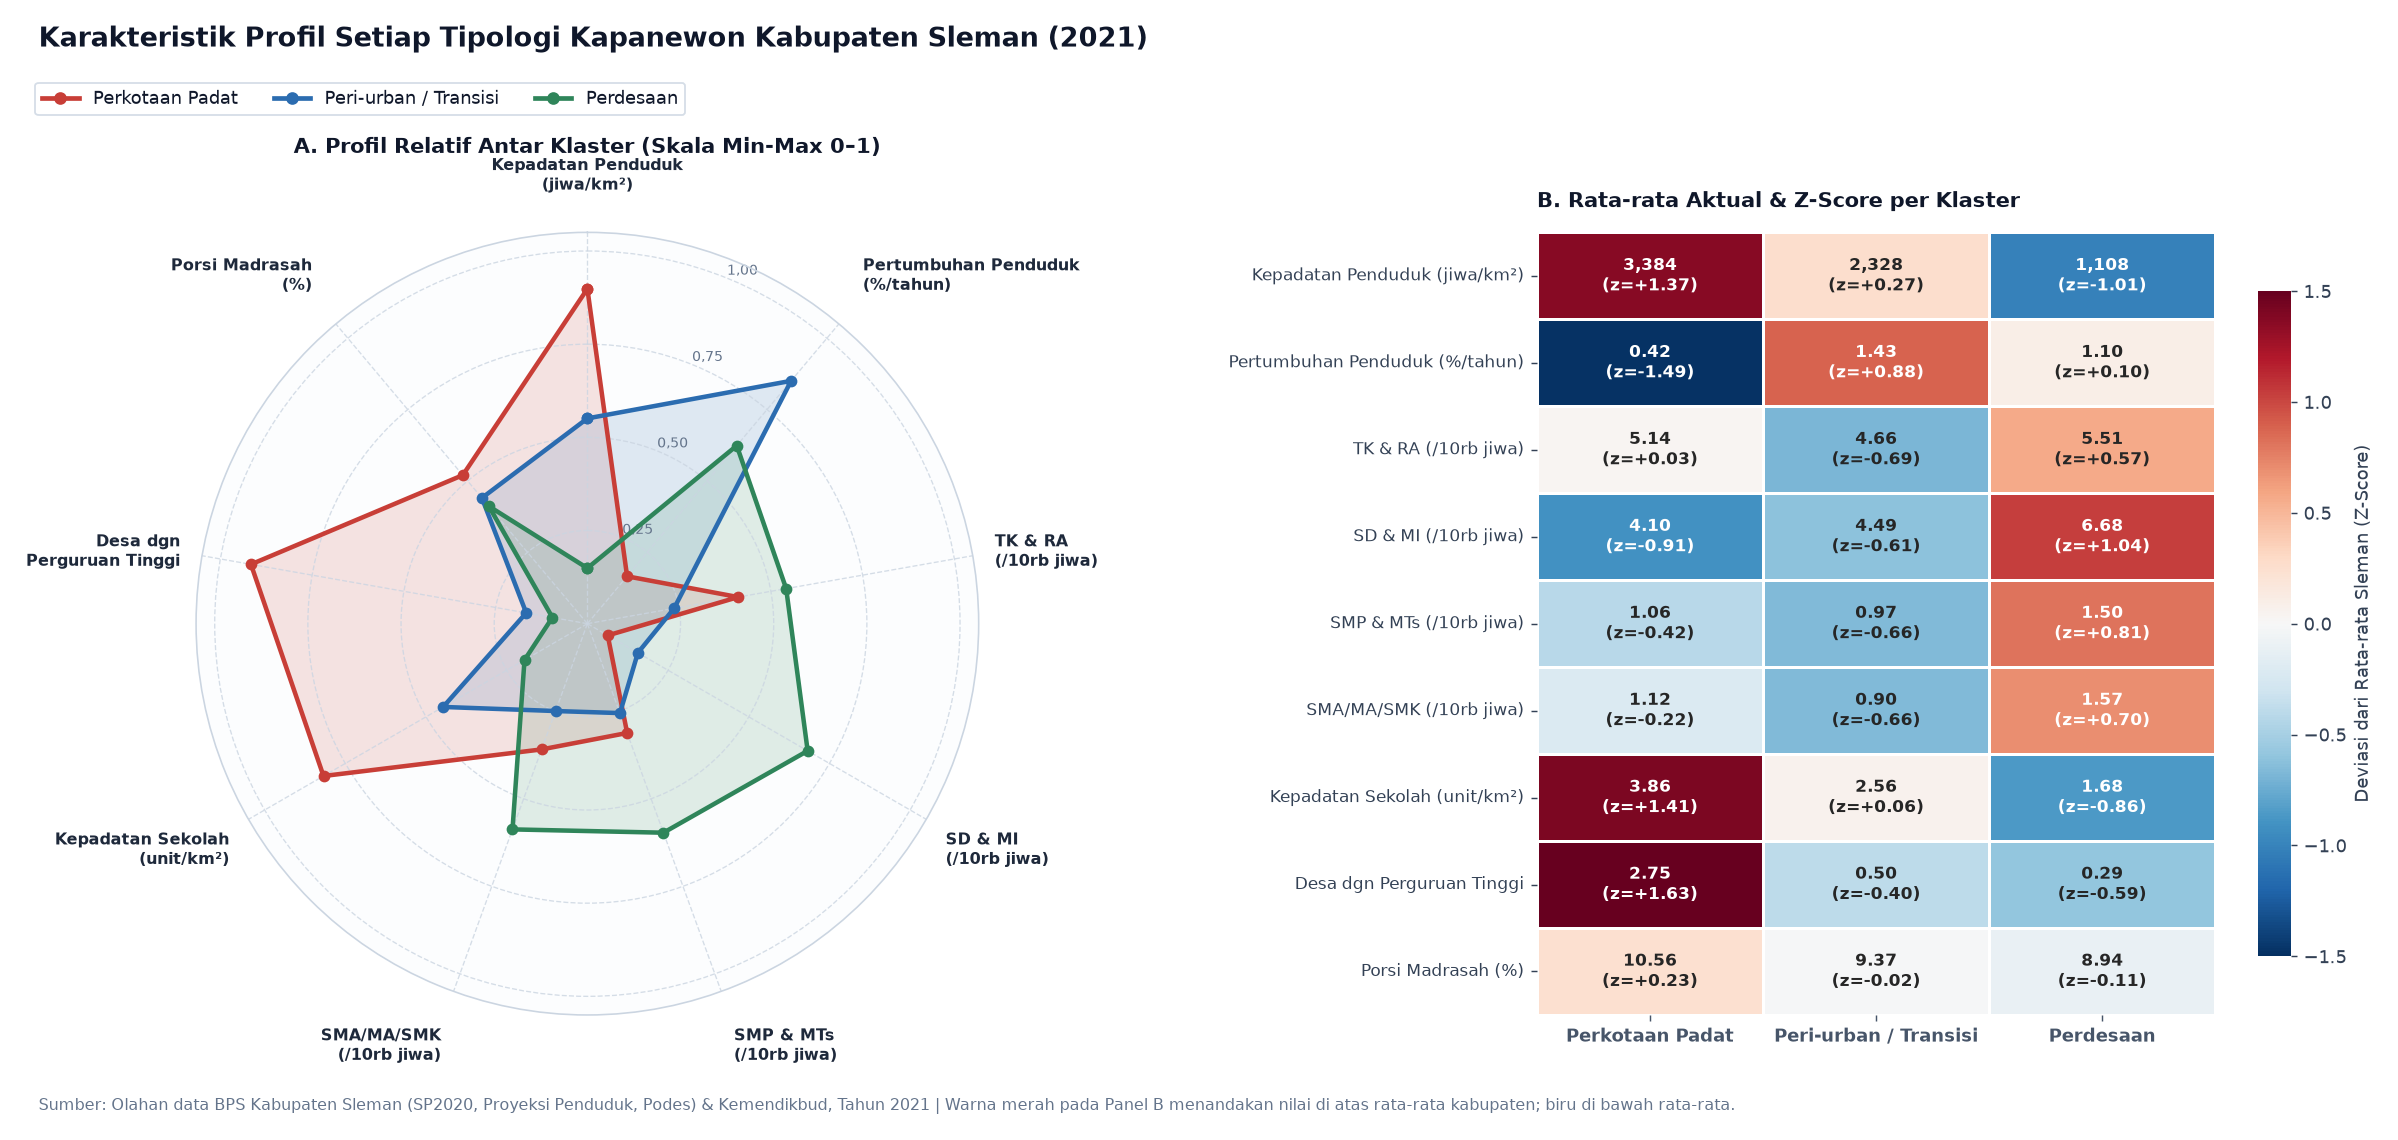

• Perkotaan Padat (4 kapanewon): Gamping, Mlati, Depok, Ngaglik
• Peri-urban / Transisi (6 kapanewon): Seyegan, Godean, Berbah, Kalasan, Ngemplak, Sleman
• Perdesaan (7 kapanewon): Moyudan, Minggir, Prambanan, Tempel, Turi, Pakem, Cangkringan


In [9]:
profil_mean = df.groupby('tipologi')[FEATURES].mean().loc[CLUSTER_NAMES]
mm = (df[FEATURES] - df[FEATURES].min()) / (df[FEATURES].max() - df[FEATURES].min())
rad = mm.groupby(df['tipologi']).mean().loc[CLUSTER_NAMES]
z_df = pd.DataFrame(X, index=df.index, columns=FEATURES)
z_prof = z_df.groupby(df['tipologi']).mean().loc[CLUSTER_NAMES]

fig = plt.figure(figsize=(19.2, 8.6))
gs = fig.add_gridspec(1, 2, width_ratios=[1.05, 1.05], wspace=0.62)

# --- Panel Kiri: Radar Chart Bebas Tumpang Tindih ---
ax_r = fig.add_subplot(gs[0, 0], polar=True)
N = len(FEATURES)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles_closed = angles + [angles[0]]

ax_r.set_theta_offset(np.pi / 2)
ax_r.set_theta_direction(-1)
ax_r.set_ylim(0, 1.05)
ax_r.set_yticks([0.25, 0.50, 0.75, 1.00])
ax_r.set_yticklabels(['0,25', '0,50', '0,75', '1,00'], fontsize=8, color='#64748B')
ax_r.set_rlabel_position(22)
ax_r.set_xticks(angles)
ax_r.set_xticklabels([])  # Gambar label manual di luar lingkaran agar tidak pernah menabrak garis
ax_r.spines['polar'].set_color('#CBD5E1')
ax_r.grid(color='#CBD5E1', linestyle='--', linewidth=0.75, alpha=0.8)

for n in CLUSTER_NAMES:
    vals = rad.loc[n].tolist()
    vals_closed = vals + [vals[0]]
    ax_r.plot(angles_closed, vals_closed, color=PALETTE[n], linewidth=2.5, marker='o', markersize=5.5, label=n)
    ax_r.fill(angles_closed, vals_closed, color=PALETTE[n], alpha=0.14)

# Penempatan label luar yang presisi berdasarkan sudut
for angle, feat in zip(angles, FEATURES):
    x_dir = np.sin(angle)
    y_dir = np.cos(angle)
    ha = 'center' if abs(x_dir) < 0.15 else ('left' if x_dir > 0 else 'right')
    va = 'center' if abs(y_dir) < 0.25 else ('bottom' if y_dir > 0 else 'top')
    r_lbl = 1.15 if abs(y_dir) > 0.7 else 1.11
    ax_r.text(angle, r_lbl, FEAT_LABEL[feat], size=9, fontweight='semibold',
              color='#1E293B', ha=ha, va=va, clip_on=False)

ax_r.set_title('A. Profil Relatif Antar Klaster (Skala Min-Max 0–1)', fontsize=11.5, fontweight='bold', pad=44)

# --- Panel Kanan: Heatmap Z-Score dengan Nilai Rata-Rata Aktual ---
ax_h = fig.add_subplot(gs[0, 1])
z_t = z_prof.T
raw_t = profil_mean.T
annot_text = pd.DataFrame(index=FEATURES, columns=CLUSTER_NAMES, dtype=object)
for f in FEATURES:
    for c in CLUSTER_NAMES:
        val = raw_t.loc[f, c]
        zv = z_t.loc[f, c]
        v_str = f'{val:,.0f}' if f == 'kepadatan' else f'{val:.2f}'
        annot_text.loc[f, c] = f'{v_str}\n(z={zv:+.2f})'

z_t.index = [FEAT_SHORT[f] for f in FEATURES]
annot_text.index = z_t.index

sns.heatmap(
    z_t, annot=annot_text, fmt='', cmap='RdBu_r', center=0, vmin=-1.5, vmax=1.5,
    linewidths=1.5, linecolor='white', ax=ax_h,
    cbar_kws={'label': 'Deviasi dari Rata-rata Sleman (Z-Score)', 'shrink': 0.85},
    annot_kws={'size': 9.2, 'weight': 'semibold'}
)
ax_h.grid(False)
ax_h.set_xticklabels(ax_h.get_xticklabels(), fontsize=9.8, fontweight='bold')
ax_h.set_yticklabels(ax_h.get_yticklabels(), rotation=0, fontsize=9.3)
ax_h.set_xlabel('')
ax_h.set_title('B. Rata-rata Aktual & Z-Score per Klaster', fontsize=11.5, fontweight='bold', loc='left', pad=14)

radar_handles = [Line2D([0], [0], color=PALETTE[n], lw=2.6, marker='o', markersize=6, label=n) for n in CLUSTER_NAMES]
fig.suptitle('Karakteristik Profil Setiap Tipologi Kapanewon Kabupaten Sleman (2021)',
             fontsize=15, fontweight='bold', x=0.02, y=0.985, ha='left')
fig.legend(handles=radar_handles, loc='upper left', bbox_to_anchor=(0.015, 0.942), ncol=len(CLUSTER_NAMES),
           frameon=True, facecolor='white', edgecolor='#CBD5E1', fontsize=10)
fig.text(0.02, 0.015, SOURCE_NOTE + ' | Warna merah pada Panel B menandakan nilai di atas rata-rata kabupaten; biru di bawah rata-rata.',
         fontsize=8.8, color='#64748B')
plt.subplots_adjust(left=0.07, right=0.96, top=0.80, bottom=0.10)
plt.savefig(FIG_DIR / '06_profil_klaster_radar_dan_bar.png')
plt.show()

for n in CLUSTER_NAMES:
    anggota = df.index[df['tipologi'] == n].tolist()
    print(f'• {n} ({len(anggota)} kapanewon): {", ".join(anggota)}')

### 6.4 Matriks Kuadran Prioritas Kebijakan Pendidikan Perkotaan
Memetakan **Laju Pertumbuhan Penduduk (2020→2021)** terhadap **Total Sekolah per 10.000 Penduduk** membantu mengidentifikasi kapanewon mana yang menghadapi tekanan pertumbuhan penduduk paling cepat namun ketersediaan sekolah relatifnya paling rendah (*Kuadran Prioritas*).

findfont: Failed to find font weight semibold, now using 700.


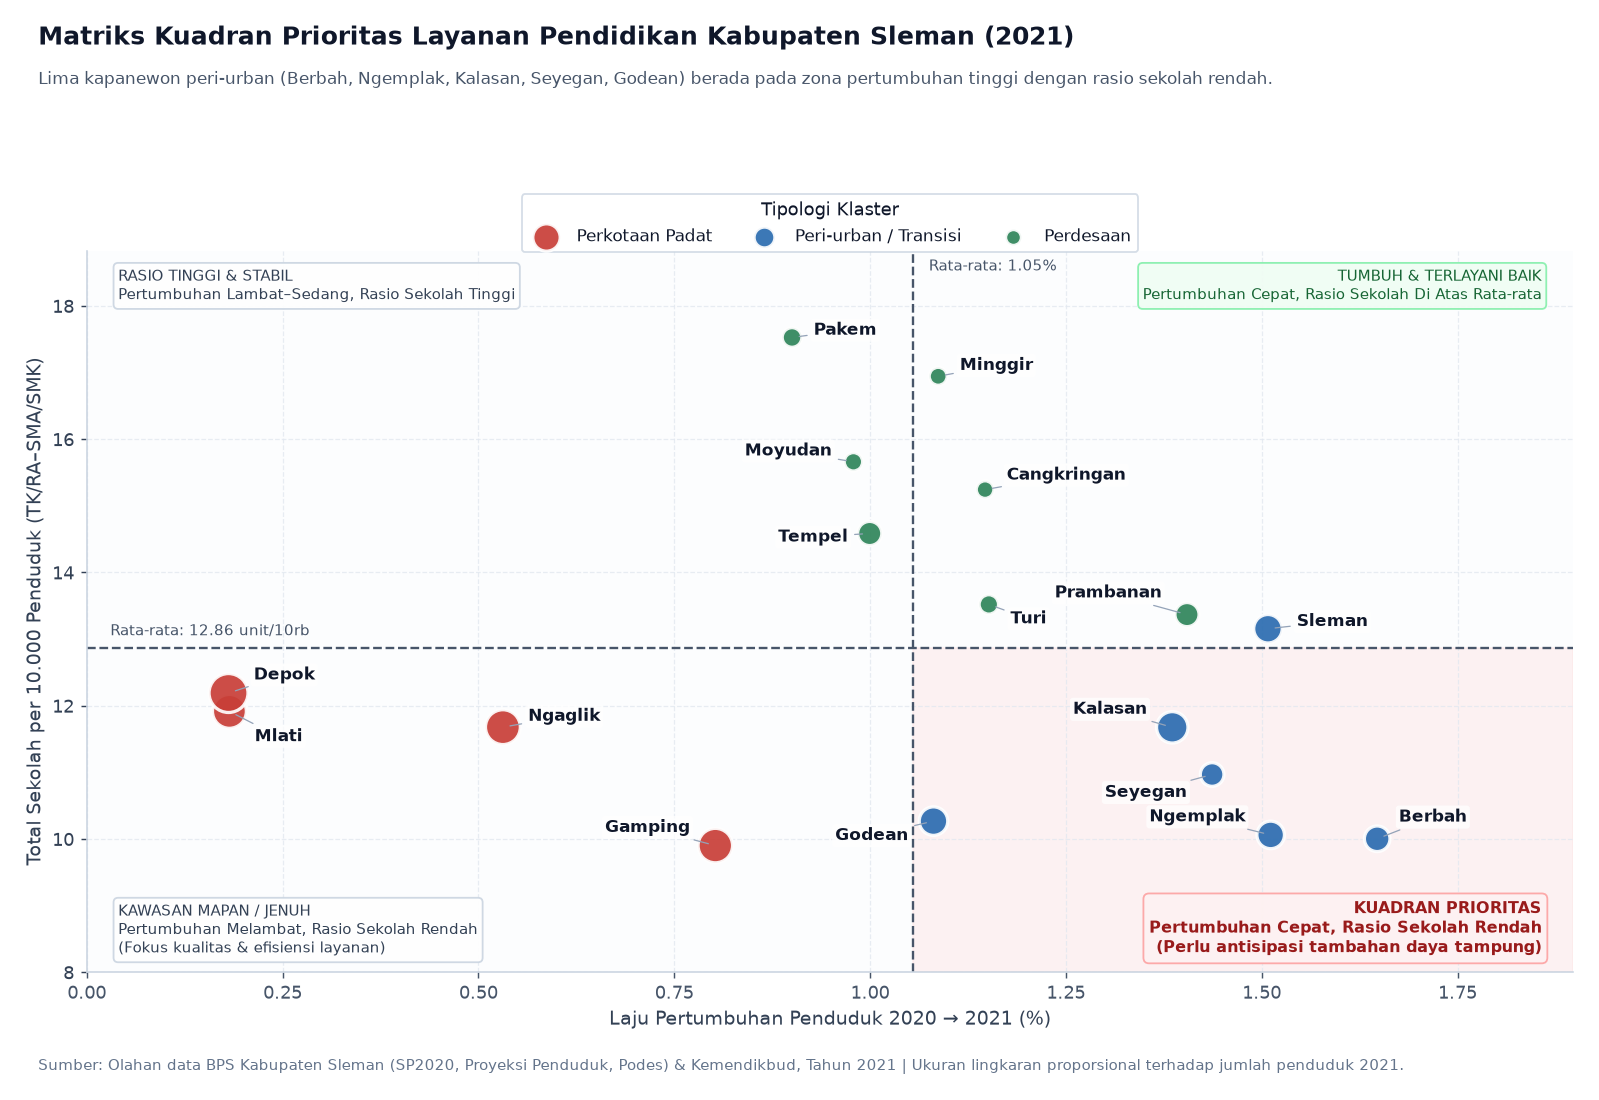

In [10]:
mean_growth = df['pertumbuhan_pct'].mean()
mean_ratio = df['sekolah_per10k'].mean()

fig, ax = plt.subplots(figsize=(12.2, 8.2))
xmin, xmax = 0.0, df['pertumbuhan_pct'].max() + 0.25
ymin, ymax = 8.0, df['sekolah_per10k'].max() + 1.3

# Sorotan lembut pada Kuadran Kanan-Bawah (Pertumbuhan Tinggi & Rasio Sekolah Rendah)
ax.axvspan(mean_growth, xmax, ymin=0, ymax=(mean_ratio - ymin) / (ymax - ymin),
           color='#FEE2E2', alpha=0.42, zorder=1)
ax.axvline(mean_growth, color='#475569', linestyle='--', linewidth=1.3, zorder=2)
ax.axhline(mean_ratio, color='#475569', linestyle='--', linewidth=1.3, zorder=2)

# Label keempat kuadran (berada di tepi kosong, tidak menabrak titik mana pun)
ax.text(xmax - 0.04, ymin + 0.22, 'KUADRAN PRIORITAS\nPertumbuhan Cepat, Rasio Sekolah Rendah\n(Perlu antisipasi tambahan daya tampung)',
        ha='right', va='bottom', fontsize=9, fontweight='bold', color='#991B1B',
        bbox=dict(boxstyle='round,pad=0.35', facecolor='#FEF2F2', edgecolor='#FCA5A5', alpha=0.95))
ax.text(xmin + 0.04, ymin + 0.22, 'KAWASAN MAPAN / JENUH\nPertumbuhan Melambat, Rasio Sekolah Rendah\n(Fokus kualitas & efisiensi layanan)',
        ha='left', va='bottom', fontsize=8.5, color='#334155',
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#CBD5E1', alpha=0.92))
ax.text(xmin + 0.04, ymax - 0.25, 'RASIO TINGGI & STABIL\nPertumbuhan Lambat–Sedang, Rasio Sekolah Tinggi',
        ha='left', va='top', fontsize=8.5, color='#334155',
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#CBD5E1', alpha=0.92))
ax.text(xmax - 0.04, ymax - 0.25, 'TUMBUH & TERLAYANI BAIK\nPertumbuhan Cepat, Rasio Sekolah Di Atas Rata-rata',
        ha='right', va='top', fontsize=8.5, color='#166534',
        bbox=dict(boxstyle='round,pad=0.3', facecolor='#F0FDF4', edgecolor='#86EFAC', alpha=0.92))

sizes = 95 + (df['penduduk'] - df['penduduk'].min()) / (df['penduduk'].max() - df['penduduk'].min()) * 370
for n in CLUSTER_NAMES:
    sub = df[df['tipologi'] == n]
    ax.scatter(sub['pertumbuhan_pct'], sub['sekolah_per10k'], s=sizes.loc[sub.index],
               color=PALETTE[n], edgecolor='white', linewidth=1.8, alpha=0.92, label=n, zorder=5)

# Offset manual agar semua 17 label terbaca bersih tanpa tumpang tindih
q_offsets = {
    'Depok': (14, 10),
    'Mlati': (14, -14),
    'Ngaglik': (14, 6),
    'Gamping': (-14, 10),
    'Pakem': (12, 4),
    'Moyudan': (-12, 6),
    'Tempel': (-12, -2),
    'Minggir': (12, 6),
    'Cangkringan': (12, 8),
    'Turi': (12, -8),
    'Godean': (-14, -8),
    'Prambanan': (-14, 12),
    'Kalasan': (-14, 10),
    'Seyegan': (-14, -10),
    'Sleman': (16, 4),
    'Ngemplak': (-14, 10),
    'Berbah': (12, 12),
}
for kec, row in df.iterrows():
    dx, dy = q_offsets.get(kec, (10, 6))
    ha = 'right' if dx < 0 else 'left'
    ax.annotate(
        kec, (row['pertumbuhan_pct'], row['sekolah_per10k']),
        xytext=(dx, dy), textcoords='offset points', ha=ha, va='center',
        fontsize=9.3, fontweight='semibold', color='#0F172A', zorder=6,
        bbox=dict(boxstyle='round,pad=0.18', facecolor='white', edgecolor='none', alpha=0.75),
        arrowprops=dict(arrowstyle='-', color='#94A3B8', lw=0.7, shrinkA=2, shrinkB=4)
    )

ax.text(mean_growth + 0.02, ymax - 0.12, f'Rata-rata: {mean_growth:.2f}%', fontsize=8.5, color='#475569', va='top')
ax.text(xmin + 0.03, mean_ratio + 0.14, f'Rata-rata: {mean_ratio:.2f} unit/10rb', fontsize=8.5, color='#475569', va='bottom')

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_xlabel('Laju Pertumbuhan Penduduk 2020 → 2021 (%)', fontsize=10.5)
ax.set_ylabel('Total Sekolah per 10.000 Penduduk (TK/RA–SMA/SMK)', fontsize=10.5)
ax.legend(title='Tipologi Klaster', loc='upper center', bbox_to_anchor=(0.5, 1.09),
          ncol=len(CLUSTER_NAMES), frameon=True, facecolor='white', edgecolor='#CBD5E1', fontsize=9.5, markerscale=0.75)

fig.suptitle('Matriks Kuadran Prioritas Layanan Pendidikan Kabupaten Sleman (2021)',
             fontsize=14, fontweight='bold', x=0.02, y=0.99, ha='left')
fig.text(0.02, 0.935, 'Lima kapanewon peri-urban (Berbah, Ngemplak, Kalasan, Seyegan, Godean) berada pada zona pertumbuhan tinggi dengan rasio sekolah rendah.',
         fontsize=9.7, color='#475569')
fig.text(0.02, 0.01, SOURCE_NOTE + ' | Ukuran lingkaran proporsional terhadap jumlah penduduk 2021.', fontsize=8.5, color='#64748B')
plt.tight_layout(rect=[0, 0.03, 1, 0.90])
plt.savefig(FIG_DIR / '07_kuadran_pertumbuhan_vs_layanan.png')
plt.show()

## 7. Peta Choropleth Spasial 17 Kapanewon Kabupaten Sleman
Memetakan hasil klasterisasi K-Means dan rasio layanan pendidikan secara geografis menggunakan batas 17 kapanewon / 86 kalurahan (`data/raw/sleman_kecamatan.geojson`, sumber HDX–BPS 2020 via `JfrAziz/indonesia-district`) dan batas luar Kabupaten Sleman (`data/raw/Sleman.geojson`, via `mahendrayudha/indonesia-geojson`).

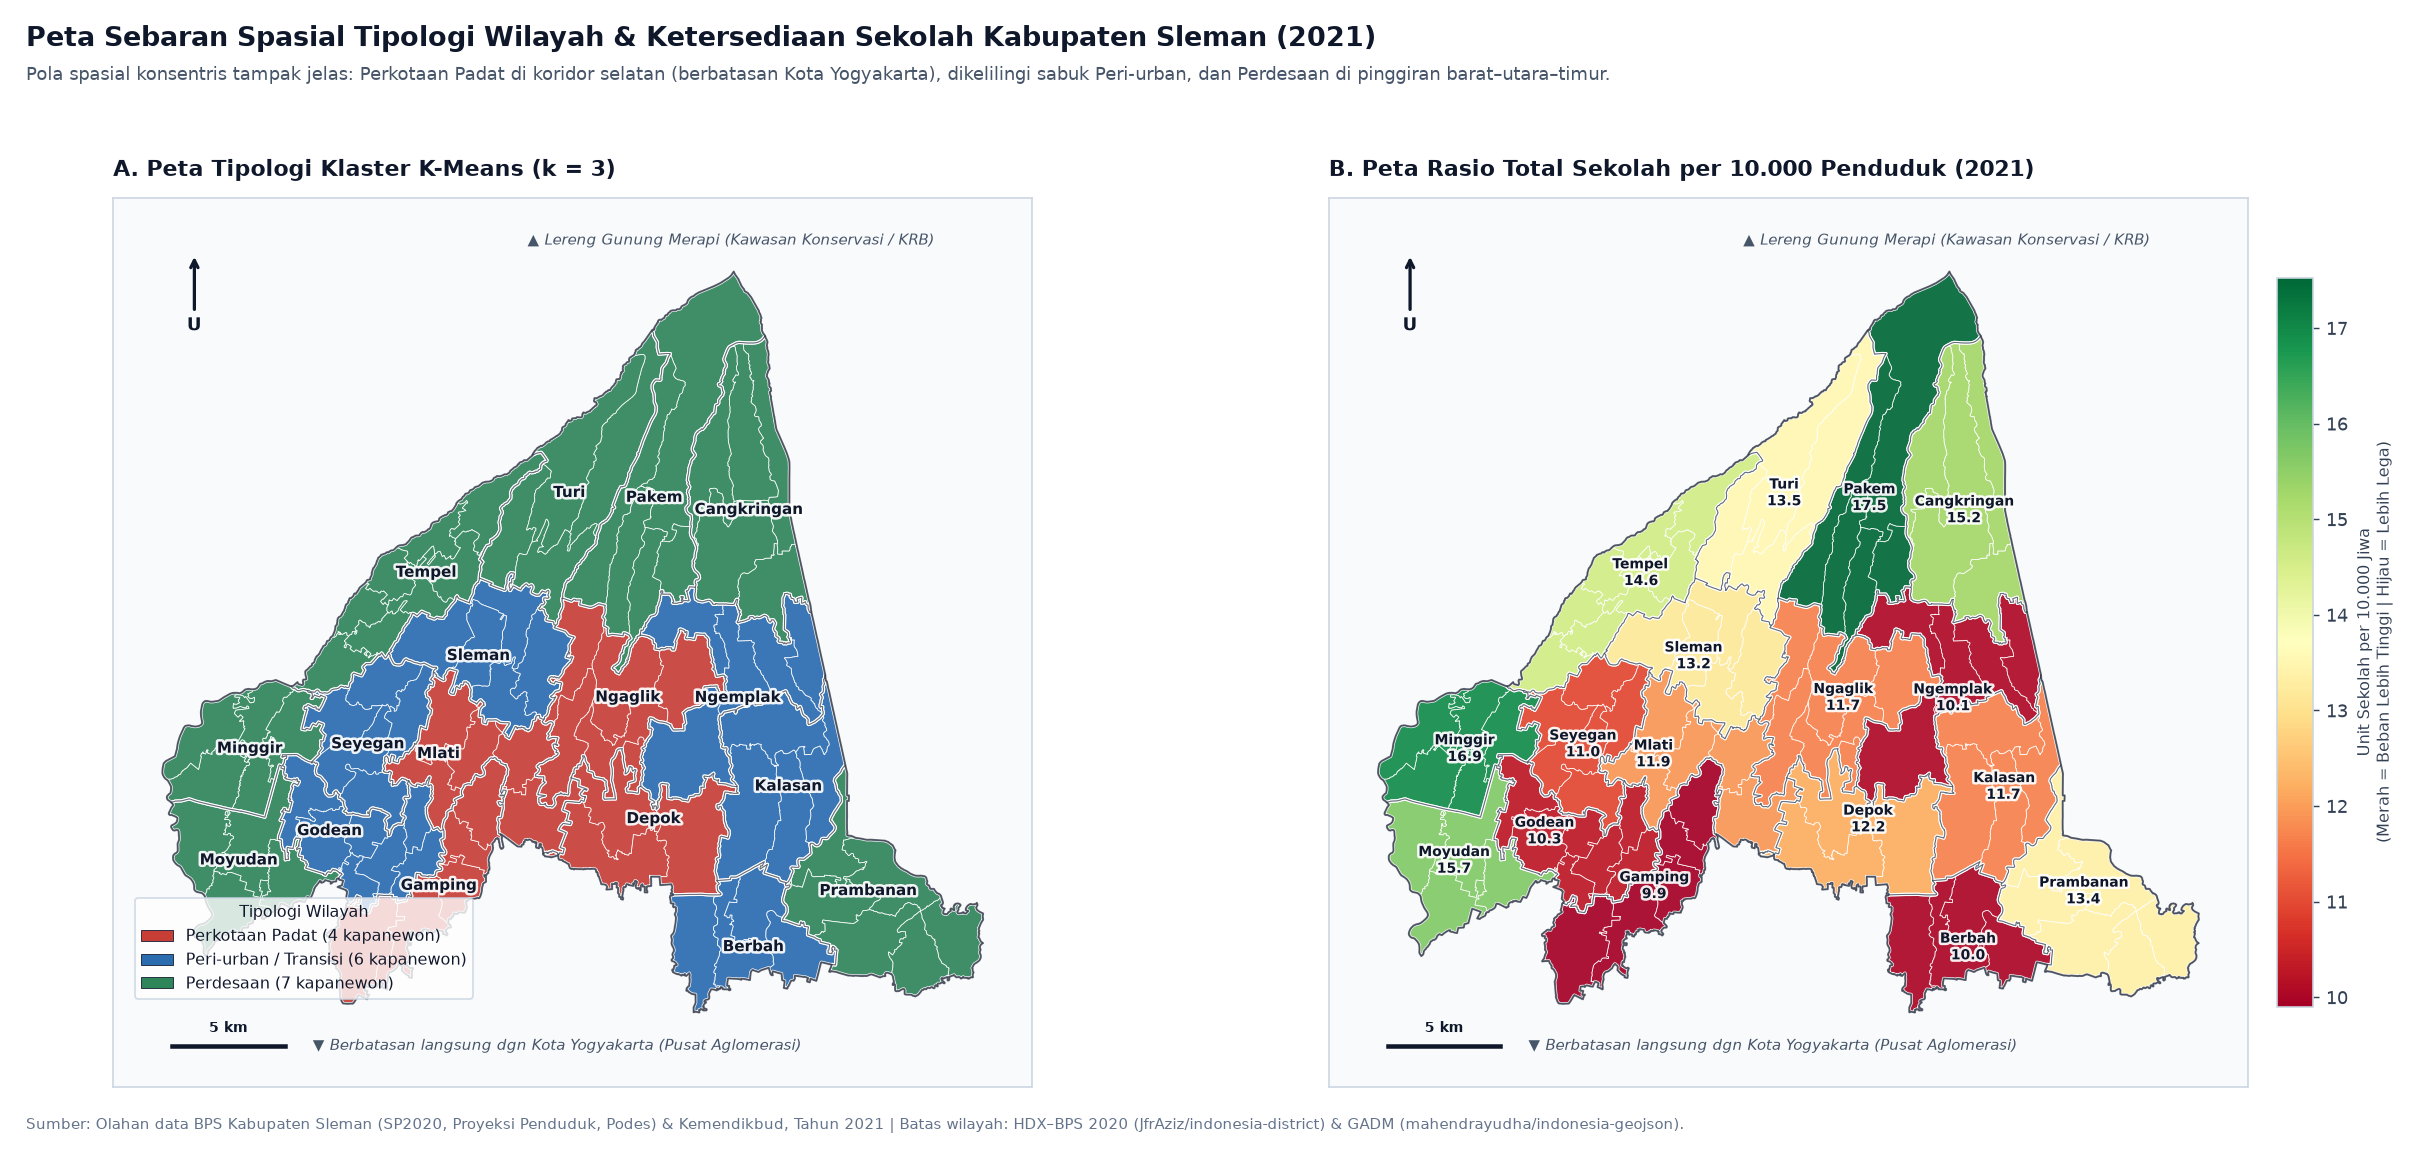

Peta choropleth tersimpan di: C:\Users\LENOVO\Documents\tugas-besar-analitika-perkotaan\output\figures\08_peta_choropleth_sleman.png


In [11]:
import json
from matplotlib.patches import Polygon as MplPolygon
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import matplotlib.patheffects as pe

GEO_KEC = RAW_DIR / 'sleman_kecamatan.geojson'
GEO_KAB = RAW_DIR / 'Sleman.geojson'

def iter_rings(geom):
    """Ambil seluruh cincin koordinat luar dari Polygon atau MultiPolygon."""
    if geom['type'] == 'Polygon':
        yield geom['coordinates'][0]
    elif geom['type'] == 'MultiPolygon':
        for poly in geom['coordinates']:
            yield poly[0]

def ring_area_centroid(ring):
    pts = np.asarray(ring, dtype=float)
    x, y = pts[:, 0], pts[:, 1]
    x2, y2 = np.roll(x, -1), np.roll(y, -1)
    cross = x * y2 - x2 * y
    area = 0.5 * np.sum(cross)
    if abs(area) < 1e-12:
        return 0.0, float(x.mean()), float(y.mean())
    cx = np.sum((x + x2) * cross) / (6.0 * area)
    cy = np.sum((y + y2) * cross) / (6.0 * area)
    return abs(area), float(cx), float(cy)

if not GEO_KEC.exists():
    print(f'File {GEO_KEC} belum tersedia -> peta choropleth dilewati.')
else:
    with open(GEO_KEC, encoding='utf-8') as f:
        gj = json.load(f)

    kec_rings = {k: [] for k in KEC}
    upper_map = {k.upper(): k for k in KEC}
    for feat in gj['features']:
        props = feat['properties']
        d_raw = str(props.get('district', props.get('NAMOBJ', props.get('NAME_3', '')))).strip().upper()
        if d_raw in upper_map:
            kec_name = upper_map[d_raw]
            for ring in iter_rings(feat['geometry']):
                kec_rings[kec_name].append(ring)

    # Jika shapely terpasang, gabungkan (dissolve) poligon kalurahan agar batas tiap kapanewon tegas
    dissolved = {}
    try:
        from shapely.geometry import shape
        from shapely.ops import unary_union
        by_kec = {k: [] for k in KEC}
        for feat in gj['features']:
            d_raw = str(feat['properties'].get('district', '')).strip().upper()
            if d_raw in upper_map:
                by_kec[upper_map[d_raw]].append(shape(feat['geometry']))
        for k, geoms in by_kec.items():
            if geoms:
                dissolved[k] = unary_union(geoms)
    except Exception:
        dissolved = {}

    centroids = {}
    for k in KEC:
        if k in dissolved:
            pt = dissolved[k].representative_point()
            centroids[k] = (pt.x, pt.y)
        else:
            tot_a, sx, sy = 0.0, 0.0, 0.0
            for r in kec_rings[k]:
                a, cx, cy = ring_area_centroid(r)
                tot_a += a; sx += a * cx; sy += a * cy
            centroids[k] = (sx / tot_a, sy / tot_a)

    label_nudge = {
        'Berbah': (0.004, -0.004),
        'Depok': (0.002, 0.002),
        'Mlati': (-0.002, 0.003),
        'Gamping': (-0.005, -0.002),
        'Godean': (-0.002, 0.001),
        'Ngaglik': (0.000, 0.002),
        'Kalasan': (0.002, -0.003),
        'Prambanan': (0.004, -0.004),
        'Cangkringan': (0.004, -0.008),
        'Pakem': (-0.002, -0.010),
        'Turi': (-0.003, -0.006),
    }

    kab_rings = []
    if GEO_KAB.exists():
        with open(GEO_KAB, encoding='utf-8') as f:
            gj_kab = json.load(f)
        for feat in gj_kab['features']:
            for r in iter_rings(feat['geometry']):
                kab_rings.append(np.asarray(r, dtype=float))

    all_pts = np.vstack([np.asarray(r) for rings in kec_rings.values() for r in rings])
    lon_min, lat_min = all_pts[:, 0].min(), all_pts[:, 1].min()
    lon_max, lat_max = all_pts[:, 0].max(), all_pts[:, 1].max()
    pad_x, pad_y = (lon_max - lon_min) * 0.06, (lat_max - lat_min) * 0.10
    cos_lat = np.cos(np.radians((lat_min + lat_max) / 2))

    fig, axes = plt.subplots(1, 2, figsize=(18.8, 8.8))
    norm_sek = mcolors.Normalize(vmin=df['sekolah_per10k'].min(), vmax=df['sekolah_per10k'].max())
    cmap_sek = plt.get_cmap('RdYlGn')

    for panel_idx, ax in enumerate(axes):
        ax.set_facecolor('#F8FAFC')
        for k in KEC:
            face = PALETTE[df.loc[k, 'tipologi']] if panel_idx == 0 else cmap_sek(norm_sek(df.loc[k, 'sekolah_per10k']))
            for ring in kec_rings[k]:
                poly = MplPolygon(ring, closed=True, facecolor=face, edgecolor='white',
                                  linewidth=0.45, alpha=0.92, zorder=2)
                ax.add_patch(poly)

        for k, geom in dissolved.items():
            geoms_iter = [geom] if geom.geom_type == 'Polygon' else list(geom.geoms)
            for g_poly in geoms_iter:
                xs, ys = g_poly.exterior.xy
                ax.plot(xs, ys, color='white', linewidth=1.8, zorder=3)
                ax.plot(xs, ys, color='#1E293B', linewidth=0.55, alpha=0.45, zorder=3.1)

        for r_kab in kab_rings:
            ax.plot(r_kab[:, 0], r_kab[:, 1], color='#0F172A', linewidth=1.15, alpha=0.6, zorder=4)

        halo = [pe.withStroke(linewidth=2.8, foreground='white', alpha=0.92)]
        for k in KEC:
            cx, cy = centroids[k]
            dx, dy = label_nudge.get(k, (0.0, 0.0))
            txt = k if panel_idx == 0 else f"{k}\n{df.loc[k, 'sekolah_per10k']:.1f}"
            fsize = 8.4 if panel_idx == 0 else 7.7
            ax.text(cx + dx, cy + dy, txt, fontsize=fsize, fontweight='bold',
                    color='#0F172A', ha='center', va='center', path_effects=halo, zorder=6)

        # Konteks geografis perkotaan (Gunung Merapi di utara, Kota Yogyakarta di selatan)
        ax.text(110.445, lat_max + pad_y * 0.42, '▲ Lereng Gunung Merapi (Kawasan Konservasi / KRB)',
                fontsize=8.5, style='italic', color='#475569', ha='center', va='center')
        ax.text(110.375, lat_min - pad_y * 0.45, '▼ Berbatasan langsung dgn Kota Yogyakarta (Pusat Aglomerasi)',
                fontsize=8.5, style='italic', color='#475569', ha='center', va='center')

        # Penunjuk arah utara (U) & skala 5 km
        ax.annotate('U', xy=(lon_min + pad_x * 0.65, lat_max + pad_y * 0.25),
                    xytext=(lon_min + pad_x * 0.65, lat_max - pad_y * 0.85),
                    arrowprops=dict(arrowstyle='->', color='#0F172A', lw=1.8),
                    ha='center', va='bottom', fontsize=10, fontweight='bold', color='#0F172A', zorder=7)
        km5_deg = 5.0 / (111.32 * cos_lat)
        sx0, sy0 = lon_min + pad_x * 0.2, lat_min - pad_y * 0.45
        ax.plot([sx0, sx0 + km5_deg], [sy0, sy0], color='#0F172A', lw=2.5, zorder=7)
        ax.text(sx0 + km5_deg / 2, sy0 + pad_y * 0.14, '5 km', ha='center', va='bottom', fontsize=8, fontweight='bold')

        ax.set_xlim(lon_min - pad_x, lon_max + pad_x)
        ax.set_ylim(lat_min - pad_y, lat_max + pad_y)
        ax.set_aspect(1.0 / cos_lat)
        ax.set_xticks([]); ax.set_yticks([])
        for sp in ax.spines.values():
            sp.set_visible(True); sp.set_color('#CBD5E1'); sp.set_linewidth(0.9)

    axes[0].set_title('A. Peta Tipologi Klaster K-Means (k = 3)', fontsize=12, fontweight='bold', loc='left', pad=12)
    handles_a = [
        mpatches.Patch(facecolor=PALETTE[n], edgecolor='#1E293B', linewidth=0.5,
                       label=f"{n} ({(df['tipologi'] == n).sum()} kapanewon)")
        for n in CLUSTER_NAMES
    ]
    axes[0].legend(handles=handles_a, title='Tipologi Wilayah', loc='lower left',
                   bbox_to_anchor=(0.015, 0.09), frameon=True, facecolor='white',
                   edgecolor='#CBD5E1', fontsize=8.8, title_fontsize=9)

    axes[1].set_title('B. Peta Rasio Total Sekolah per 10.000 Penduduk (2021)', fontsize=12, fontweight='bold', loc='left', pad=12)
    sm = cm.ScalarMappable(norm=norm_sek, cmap=cmap_sek)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=axes[1], fraction=0.038, pad=0.025, shrink=0.82)
    cbar.set_label('Unit Sekolah per 10.000 Jiwa\n(Merah = Beban Lebih Tinggi | Hijau = Lebih Lega)', fontsize=9)

    fig.suptitle('Peta Sebaran Spasial Tipologi Wilayah & Ketersediaan Sekolah Kabupaten Sleman (2021)',
                 fontsize=15, fontweight='bold', x=0.02, y=0.98, ha='left')
    fig.text(0.02, 0.932, 'Pola spasial konsentris tampak jelas: Perkotaan Padat di koridor selatan (berbatasan Kota Yogyakarta), dikelilingi sabuk Peri-urban, dan Perdesaan di pinggiran barat–utara–timur.',
             fontsize=9.8, color='#475569')
    fig.text(0.02, 0.015, SOURCE_NOTE + ' | Batas wilayah: HDX–BPS 2020 (JfrAziz/indonesia-district) & GADM (mahendrayudha/indonesia-geojson).',
             fontsize=8.5, color='#64748B')
    plt.tight_layout(rect=[0, 0.035, 1, 0.90])
    plt.savefig(FIG_DIR / '08_peta_choropleth_sleman.png')
    plt.show()
    print('Peta choropleth tersimpan di:', FIG_DIR / '08_peta_choropleth_sleman.png')

## 8. Ekspor Tabel Hasil & Catatan Metodologis

In [12]:
df.round(2).to_csv(PROC_DIR / 'hasil_klaster_kapanewon.csv')
ringkasan = df.groupby('tipologi')[['penduduk', 'kepadatan', 'pertumbuhan_pct', 'total_sekolah', 'sekolah_per10k', 'sekolah_per_km2', 'desa_PT']].mean().loc[CLUSTER_NAMES]
ringkasan['jumlah_kapanewon'] = df.groupby('tipologi').size().loc[CLUSTER_NAMES]
ringkasan.round(2).to_csv(PROC_DIR / 'ringkasan_profil_klaster.csv')

print('File hasil tersimpan di data/processed/:')
for p in sorted(PROC_DIR.glob('*.csv')):
    print(' -', p.name)
print('\nGrafik tersimpan di output/figures/:')
for p in sorted(FIG_DIR.glob('*.png')):
    print(' -', p.name)

display(df[['penduduk', 'kepadatan', 'pertumbuhan_pct', 'total_sekolah', 'sekolah_per10k', 'tipologi']].sort_values(['tipologi', 'kepadatan'], ascending=[True, False]).round(2))

File hasil tersimpan di data/processed/:
 - dataset_kapanewon_2021.csv
 - hasil_klaster_kapanewon.csv
 - ringkasan_profil_klaster.csv

Grafik tersimpan di output/figures/:
 - 01_korelasi_fitur.png
 - 02_evaluasi_jumlah_klaster.png
 - 03_dendrogram_hierarki.png
 - 04_peringkat_kepadatan_dan_sekolah.png
 - 05_pca_biplot_klaster.png
 - 06_profil_klaster_radar_dan_bar.png
 - 07_kuadran_pertumbuhan_vs_layanan.png
 - 08_peta_choropleth_sleman.png


,penduduk,kepadatan,pertumbuhan_pct,total_sekolah,sekolah_per10k,tipologi
kapanewon,,,,,,
Tempel,54164.0,1667.10,1.00,79.0,14.59,Perdesaan
Prambanan,53859.0,1302.52,1.40,72.0,13.37,Perdesaan
Moyudan,33842.0,1225.27,0.98,53.0,15.66,Perdesaan
Minggir,32459.0,1190.28,1.09,55.0,16.94,Perdesaan
Pakem,37656.0,858.94,0.90,66.0,17.53,Perdesaan
Turi,36980.0,858.20,1.15,50.0,13.52,Perdesaan
Cangkringan,31488.0,656.14,1.15,48.0,15.24,Perdesaan
Godean,73036.0,2721.16,1.08,75.0,10.27,Peri-urban / Transisi
Berbah,59976.0,2608.79,1.65,60.0,10.00,Peri-urban / Transisi


### Catatan & Keterbatasan Analisis
- **Ukuran sampel ($n = 17$):** Jumlah observasi relatif kecil sehingga hasil klasterisasi sensitif terhadap pilihan fitur dan nilai $k$. Skor Silhouette ($0{,}298$) menunjukkan pemisahan klaster kategori moderat; kestabilan hasil divalidasi dengan *Hierarchical Clustering* ($\text{ARI} = 0{,}796$).
- **Sumber kependudukan:** Angka penduduk menggunakan **Proyeksi Penduduk BPS 2015–2045** dan kepadatan **SP2020** (berbeda dengan registrasi administrasi Dukcapil).
- **Cakupan pendidikan:** Data jumlah sekolah per kapanewon berhenti di **2021** dan mencerminkan jumlah unit fisik (bukan kapasitas ruang kelas maupun kualitas/akreditasi).
- **Interpretasi klaster:** Penamaan tipologi (*Perkotaan Padat*, *Peri-urban / Transisi*, *Perdesaan*) merupakan interpretasi analitis berdasarkan profil rata-rata indikator, bukan label bawaan algoritma.